## Analyze Data from Fischbach Lab 

In [50]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib import patheffects
import scipy.optimize
import scipy.stats
from scipy.stats import gmean
from scipy.optimize import minimize, LinearConstraint, Bounds, NonlinearConstraint, linprog
from sklearn.cluster import SpectralClustering, KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler, RobustScaler, Normalizer
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import silhouette_score
from sklearn.linear_model import LinearRegression
from math import erf
import multiprocessing as mp
import seaborn as sns
# from tqdm import tqdm
from joblib import Parallel, delayed
import itertools
import os
import time
import pandas as pd
import plotly.graph_objects as go

plt.style.use('/Users/ObinnaUkogu/Desktop/custom.mplstyle')
%config InlineBackend.figure_format = 'retina'

# set colors
ito_colors = [
    '#999999',   # Grey
    '#E69F00',  # Orange
    '#56B4E9',  # Sky Blue
    '#009E73',  # Bluish Green
    '#F0E442',  # Yellow
    '#0072B2',  # Blue
    '#D55E00',  # Vermillion
    '#CC79A7',  # Reddish Purple
    '#999933', # Olive
    '#AA4499' # Pink purple
]
custom_cmap_discrete = ListedColormap(ito_colors)

In [2]:
# 2. Define the scaling function
def clr_transform(column):
    # Calculate the geometric mean of the column
    # gmean handles NaNs by default with 'omit', but ensure data is positive
    norm_colum = column/np.sum(column)
    col_gmean = gmean(norm_colum, nan_policy='omit')
    
    # Scale the column by dividing each value by the geometric mean
    scaled_column = norm_colum / col_gmean
    return np.log(scaled_column)

def alr_transform(column, ref = 'first'):
    # Calculate the additive log tranform
    # Scale the column by dividing each value by the first cluster
    if ref == 'first':
        norm_colum = column/column[0]
    elif ref == 'max':
        norm_colum = column/np.amax(column)
        
    return np.log(norm_colum)

#### Import datasets

In [3]:
# Import experimental data sets on T cell expansion
coverage_data = pd.read_csv('./data/nagashima_fig2.csv')
cross_reactivity_data = pd.read_csv('./data/nagashima_fig3.csv')
day14_abundance_data = pd.read_csv('./data/nagashima_extfig7a.csv')
amino_dropout_abundance_data = pd.read_csv('./data/cheng_tableS3.csv')
day0_abundance_data = pd.read_csv('./data/wang_tableS2_averageB6mice.csv')
feces_abundance_data = pd.read_csv('./data/wang_tableS2_fecesB6mice.csv')
strain_dropout_abundance_data = pd.read_csv('./data/wang_tableS3_cecum.csv')

# Make unique_id
coverage_data['strain_id'] = coverage_data['Strain_Name'].str.lower().str.strip().str.replace(r'\s+', ' ', regex=True)
cross_reactivity_data['strain_id'] = cross_reactivity_data['alt_Strain_Name'].str.lower().str.strip().str.replace(r'\s+', ' ', regex=True)
feces_abundance_data['strain_id'] = feces_abundance_data['alt_Strain_Name'].str.lower().str.strip().str.replace(r'\s+', ' ', regex=True)
day14_abundance_data['strain_id'] = day14_abundance_data['alt_Strain_Name'].str.lower().str.strip().str.replace(r'\s+', ' ', regex=True)
day0_abundance_data['strain_id'] = day0_abundance_data['alt_Strain_Name'].str.lower().str.strip().str.replace(r'\s+', ' ', regex=True)
amino_dropout_abundance_data['strain_id'] = amino_dropout_abundance_data['alt_Strain_Name'].str.lower().str.strip().str.replace(r'\s+', ' ', regex=True)
strain_dropout_abundance_data['strain_id'] = strain_dropout_abundance_data['alt_Strain_Name'].str.lower().str.strip().str.replace(r'\s+', ' ', regex=True)

amino_dropout_abundance_data.loc[:,'day2_log10_abundance'] = amino_dropout_abundance_data.day2_abundance
amino_dropout_abundance_data.loc[:,'day2_abundance'] = 100*10**(amino_dropout_abundance_data.day2_abundance)

# make immune response flag
coverage_data['imm_resp_flag'] = (coverage_data[['hCom1d_pTreg_pval', 'hCom1d_pTreg_pval', 'hCom1d_FR4_Th_pval']] <= 0.05).any(axis="columns")
coverage_data['sig_imm_resp_flag'] = (coverage_data[['hCom1d_pTreg_discovery', 'hCom1d_pTreg_discovery', 'hCom1d_FR4_Th_discovery']] == 'Yes').any(axis="columns")


# Compute mean abundance
feces_abundance_data.loc[:, 'wk1_mean_abundance'] = np.mean(feces_abundance_data[['Batch1_week1_m1','Batch1_week1_m2', 'Batch1_week1_m3', 
                                                                             'Batch1_week1_m4','Batch1_week1_m5']], axis = 1)
feces_abundance_data.loc[:, 'wk2_mean_abundance'] = np.mean(feces_abundance_data[['Batch1_week2_m1', 'Batch1_week2_m2','Batch1_week2_m3', 
                                                                             'Batch1_week2_m4', 'Batch1_week2_m5']], axis = 1)
feces_abundance_data.loc[:, 'wk3_mean_abundance'] = np.mean(feces_abundance_data[['Batch1_week3_m1', 'Batch1_week3_m2', 'Batch1_week3_m3', 
                                                                             'Batch1_week3_m4', 'Batch1_week3_m5']], axis = 1)
feces_abundance_data.loc[:, 'wk4_mean_abundance'] = np.mean(feces_abundance_data[['Batch1_week4_m1','Batch1_week4_m2', 'Batch1_week4_m3', 'Batch1_week4_m4',
                                                                             'Batch1_week4_m5', 'Batch2_week4_m1', 'Batch2_week4_m2',
                                                                             'Batch2_week4_m3', 'Batch3_week4_m1', 'Batch3_week4_m2',
                                                                             'Batch3_week4_m3', 'Batch3_week4_m4', 'Batch3_week4_m5']], axis = 1)

# Compute standard deviation of abundance
feces_abundance_data.loc[:, 'wk1_std_abundance'] = np.std(feces_abundance_data[['Batch1_week1_m1','Batch1_week1_m2', 'Batch1_week1_m3', 
                                                                             'Batch1_week1_m4','Batch1_week1_m5']], axis = 1)
feces_abundance_data.loc[:, 'wk2_std_abundance'] = np.std(feces_abundance_data[['Batch1_week2_m1', 'Batch1_week2_m2','Batch1_week2_m3', 
                                                                             'Batch1_week2_m4', 'Batch1_week2_m5']], axis = 1)
feces_abundance_data.loc[:, 'wk3_std_abundance'] = np.std(feces_abundance_data[['Batch1_week3_m1', 'Batch1_week3_m2', 'Batch1_week3_m3', 
                                                                             'Batch1_week3_m4', 'Batch1_week3_m5']], axis = 1)
feces_abundance_data.loc[:, 'wk4_std_abundance'] = np.std(feces_abundance_data[['Batch1_week4_m1','Batch1_week4_m2', 'Batch1_week4_m3', 'Batch1_week4_m4',
                                                                             'Batch1_week4_m5', 'Batch2_week4_m1', 'Batch2_week4_m2',
                                                                             'Batch2_week4_m3', 'Batch3_week4_m1', 'Batch3_week4_m2',
                                                                             'Batch3_week4_m3', 'Batch3_week4_m4', 'Batch3_week4_m5']], axis = 1)
add_fecal_abundance_vars = ['Batch1_week1_m1',
       'Batch1_week1_m2', 'Batch1_week1_m3', 'Batch1_week1_m4',
       'Batch1_week1_m5', 'Batch1_week2_m1', 'Batch1_week2_m2',
       'Batch1_week2_m3', 'Batch1_week2_m4', 'Batch1_week2_m5',
       'Batch1_week3_m1', 'Batch1_week3_m2', 'Batch1_week3_m3',
       'Batch1_week3_m4', 'Batch1_week3_m5', 'Batch1_week4_m1',
       'Batch1_week4_m2', 'Batch1_week4_m3', 'Batch1_week4_m4',
       'Batch1_week4_m5', 'Batch2_week4_m1', 'Batch2_week4_m2',
       'Batch2_week4_m3', 'Batch3_week4_m1', 'Batch3_week4_m2',
       'Batch3_week4_m3', 'Batch3_week4_m4', 'Batch3_week4_m5',
                           'wk1_mean_abundance','wk2_mean_abundance', 'wk3_mean_abundance','wk4_mean_abundance']
# Merge data sets
full_data = coverage_data[['strain_id', 'Strain_Name','GF_pTreg_Average', 'hCom1d_pTreg_Average', 'GF_Th17_Average', 'hCom1d_Th17_Average', 'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average', 'imm_resp_flag', 'sig_imm_resp_flag']].merge(day14_abundance_data[['strain_id', 'day14_abundance']], how = 'left', on = 'strain_id', validate = 'one_to_one',
                                ).merge(feces_abundance_data.loc[feces_abundance_data.strain_id.notna(),['strain_id', 'Phyla'] + add_fecal_abundance_vars], how = 'left', on = 'strain_id', validate = 'one_to_one'
                                       ).merge(day0_abundance_data.loc[day0_abundance_data.strain_id.notna(),['strain_id', 'day0_abundance']], how = 'left', on = 'strain_id', validate = 'one_to_one'
                                       ).merge(amino_dropout_abundance_data.loc[amino_dropout_abundance_data.strain_id.notna(),['strain_id', 'day2_abundance']], how = 'left', on = 'strain_id', validate = 'one_to_one'
                                       )

# full_data = coverage_data.merge(day14_abundance_data[['alt_Strain_Name', 'day14_abundance']], how = 'left', left_on = 'Strain_Name', validate = 'one_to_one',
#                                 right_on = 'alt_Strain_Name').merge(amino_dropout_abundance_data.loc[amino_dropout_abundance_data.alt_Strain_Name.notna(),['alt_Strain_Name', 'day2_abundance']], how = 'left', left_on = 'alt_Strain_Name', validate = 'one_to_one',
#                                                                     right_on = 'alt_Strain_Name').merge(day0_abundance_data.loc[day0_abundance_data.alt_Strain_Name.notna(), ['alt_Strain_Name', 'day0_abundance', 'day28_abundance']], how = 'left', left_on = 'alt_Strain_Name', validate = 'one_to_one', 
#                                                                     right_on = 'alt_Strain_Name')

In [4]:
# pd.set_option('display.max_rows', None)
# coverage_data[['strain_id', 'imm_resp_flag', 'hCom1d_pTreg_discovery', 'hCom1d_pTreg_discovery', 'hCom1d_FR4_Th_discovery']]

#### Microbial abundance data for week 0 (inoculum) to week 4 (post-inoculation)
This data comes from multiple sources

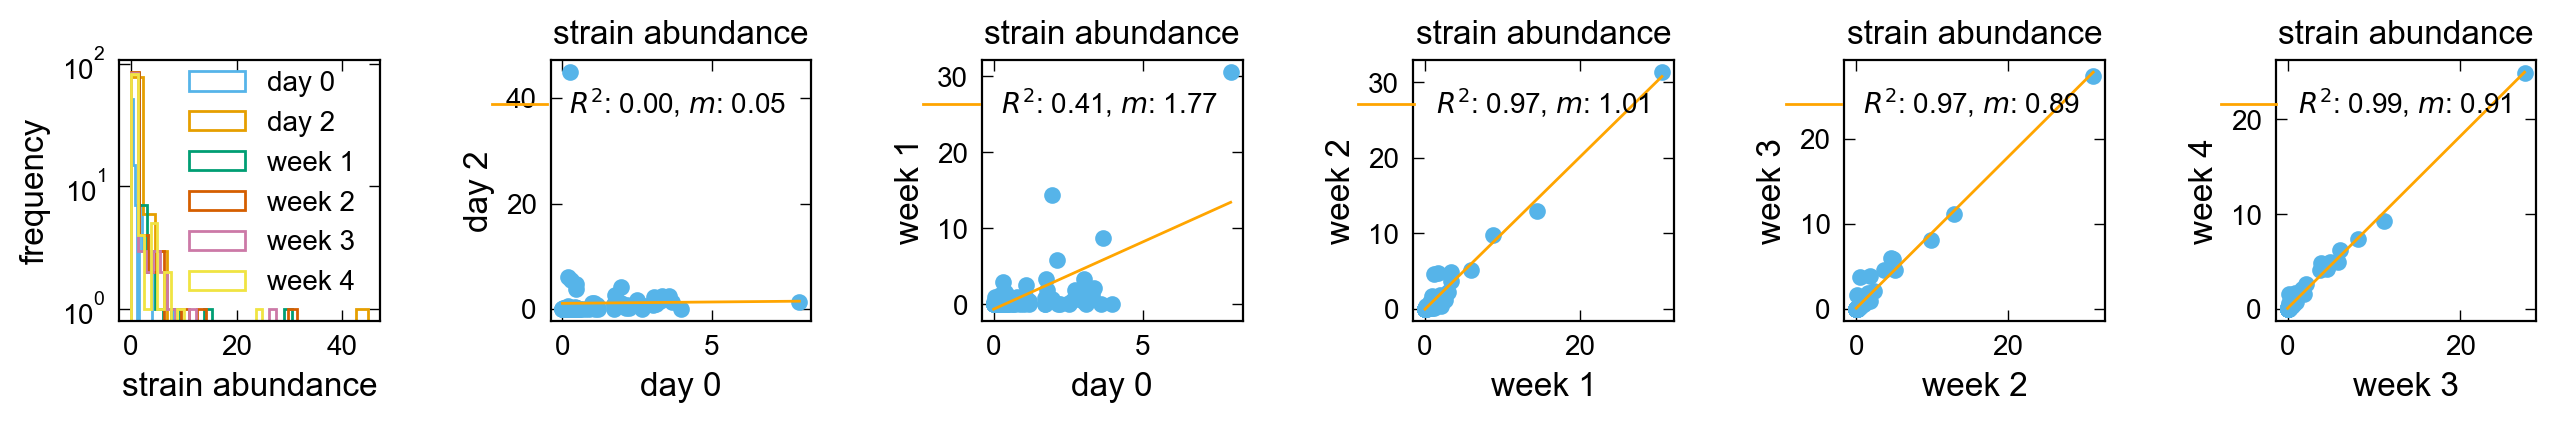

In [5]:
# Plot figures
fig, axs = plt.subplots(1, 6, figsize=(13.0, 2.0), sharex = False, constrained_layout=True)

labels = [['strain abundance', 'frequency'], 
          ['day 0', 'day 2'], ['day 0', 'week 1'], ['week 1', 'week 2'], ['week 2', 'week 3'], ['week 3', 'week 4']]
var_list = [["day0_abundance", "day2_abundance"],
            ["day0_abundance", "wk1_mean_abundance"],
            ["wk1_mean_abundance", "wk2_mean_abundance"],
            ["wk2_mean_abundance", "wk3_mean_abundance"],
            ["wk3_mean_abundance", "wk4_mean_abundance"]]

axs[0].hist(full_data.day0_abundance, bins = 20, log = True, histtype = 'step', label = 'day 0');
axs[0].hist(full_data.day2_abundance, bins = 20, log = True, histtype = 'step', label = 'day 2');
axs[0].hist(full_data.wk1_mean_abundance, bins = 20, log = True, histtype = 'step', label = 'week 1');
axs[0].hist(full_data.wk2_mean_abundance, bins = 20, log = True, histtype = 'step', label = 'week 2');
axs[0].hist(full_data.wk3_mean_abundance, bins = 20, log = True, histtype = 'step', label = 'week 3');
axs[0].hist(full_data.wk4_mean_abundance, bins = 20, log = True, histtype = 'step', label = 'week 4');

for i, u in enumerate(var_list):
    axs[i + 1].scatter(full_data[u[0]], full_data[u[1]], marker = 'o')
    mask = ~np.isnan(full_data[u[0]]) & ~np.isnan(full_data[u[1]])
    m, b, r_value, p_value, std_err = scipy.stats.linregress(full_data[u[0]][mask], full_data[u[1]][mask])
    axs[i + 1].plot(np.unique(full_data[u[0]][mask]), m*np.unique(full_data[u[0]][mask]) + b, 
                    color = 'orange', label = r'$R^2$: ' + str("{:.2f}".format(r_value**2)) + r', $m$: ' + str("{:.2f}".format(m)))

for j, ax in enumerate(axs.flat):
    ax.legend()
    if j >= 1:
        # ax.plot([0, 40], [0,40])
        # ax.semilogy()
        # ax.semilogx()
        ax.set_title('strain abundance', fontsize = 12) 
        
    ax.set_xlabel(labels[j][0], fontsize = 12)
    ax.set_ylabel(labels[j][1], fontsize = 12)
        
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

# plt.savefig('_figs/fig5_'+comment+'-perf_perturb_design'+'.pdf', format="pdf", transparent=True, dpi=300)

Day 2 data from Cheng et al (2022) is weird. There's a big change in the abundance of Lactococcus lactis subsp. lactis Il1403 from day 0 to day 2 in the data. The inoculum (day 0) does not reflect anything about the ecology of the consortium as it is made by pooling samples of each microbe grown separately in an ideal medium.

##### Microbial abundance trajectories over time: week 0 to week 4
This data is for a microbial consortium that is very similar to hCom1d. The differences are all(?) very low abundance strains.

/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/numpy/lib/function_base.py:2742: RuntimeWarning: invalid value encountered in subtract
  X -= avg[:, None]
/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/numpy/lib/function_base.py:2742: RuntimeWarning: invalid value encountered in subtract
  X -= avg[:, None]
/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/numpy/lib/function_base.py:2742: RuntimeWarning: invalid value encountered in subtract
  X -= avg[:, None]
/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/numpy/lib/function_base.py:2742: RuntimeWarning: invalid value encountered in subtract
  X -= avg[:, None]
/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/numpy/lib/function_base.py:2742: Runt

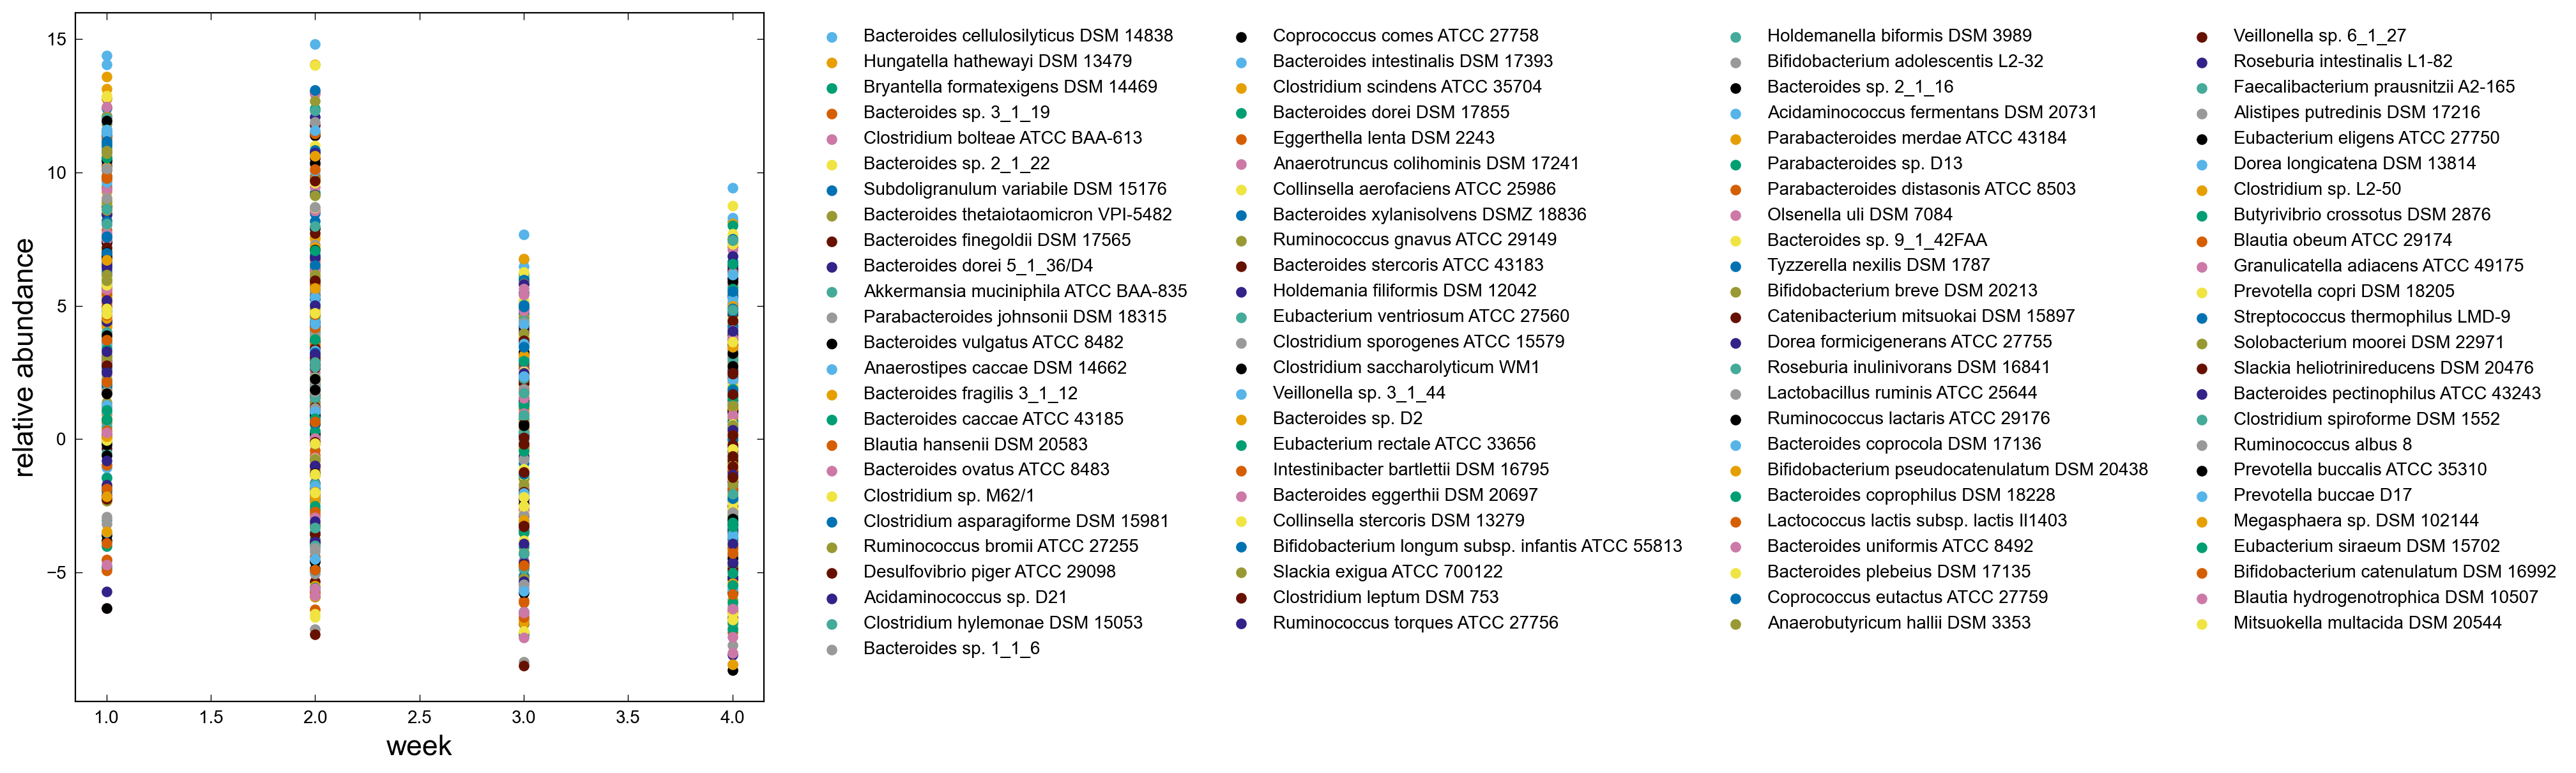

In [6]:
# Using fecal matter data from Wang et al (2023)
fig, ax = plt.subplots(1, 1, figsize=(7.0, 7.0), sharex = False, constrained_layout=True)

var_list = ['Batch1_week1_m1',
       'Batch1_week1_m2', 'Batch1_week1_m3', 'Batch1_week1_m4',
       'Batch1_week1_m5', 'Batch1_week2_m1', 'Batch1_week2_m2',
       'Batch1_week2_m3', 'Batch1_week2_m4', 'Batch1_week2_m5',
       'Batch1_week3_m1', 'Batch1_week3_m2', 'Batch1_week3_m3',
       'Batch1_week3_m4', 'Batch1_week3_m5', 'Batch1_week4_m1',
       'Batch1_week4_m2', 'Batch1_week4_m3', 'Batch1_week4_m4',
       'Batch1_week4_m5', 'Batch2_week4_m1', 'Batch2_week4_m2',
       'Batch2_week4_m3', 'Batch3_week4_m1', 'Batch3_week4_m2',
       'Batch3_week4_m3', 'Batch3_week4_m4', 'Batch3_week4_m5']

data = feces_abundance_data.sort_values(by='Batch1_week2_m1', ascending= False)
data[var_list] = data[var_list].apply(alr_transform, axis=0)

strain_list = data.loc[data.strain_id.notna()].alt_Strain_Name

for strain in strain_list:
    #full_data.loc[full_data.alt_Strain_Name == strain].day0_abundance.value
    y_data = data.loc[data.alt_Strain_Name == strain, var_list].values.ravel().tolist()
    x_data = [1, 1, 1, 1, 1, 2,2,2,2,2,3,3,3,3,3,4,4,4,4,4,4,4,4,4,4,4,4,4]
    ax.scatter(x_data, y_data, label = strain)
    m, b, r_value, p_value, std_err = scipy.stats.linregress(x_data, y_data)
    ax.plot(np.unique(x_data), 
            m*np.unique(x_data) + b)

    
ax.legend(bbox_to_anchor=(1.05, 1.0), fontsize=10, framealpha=0, ncol = 4)

ax.set_xlabel('week', fontsize = 16)
ax.set_ylabel('relative abundance', fontsize = 16)
# ax.semilogy()
ax.set_box_aspect(1)
ax.minorticks_off()
ax.tick_params(axis='both', which='major', labelsize=10)
ax.xaxis.set_tick_params(labeltop=False)

/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/IPython/core/events.py:82: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  func(*args, **kwargs)
/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


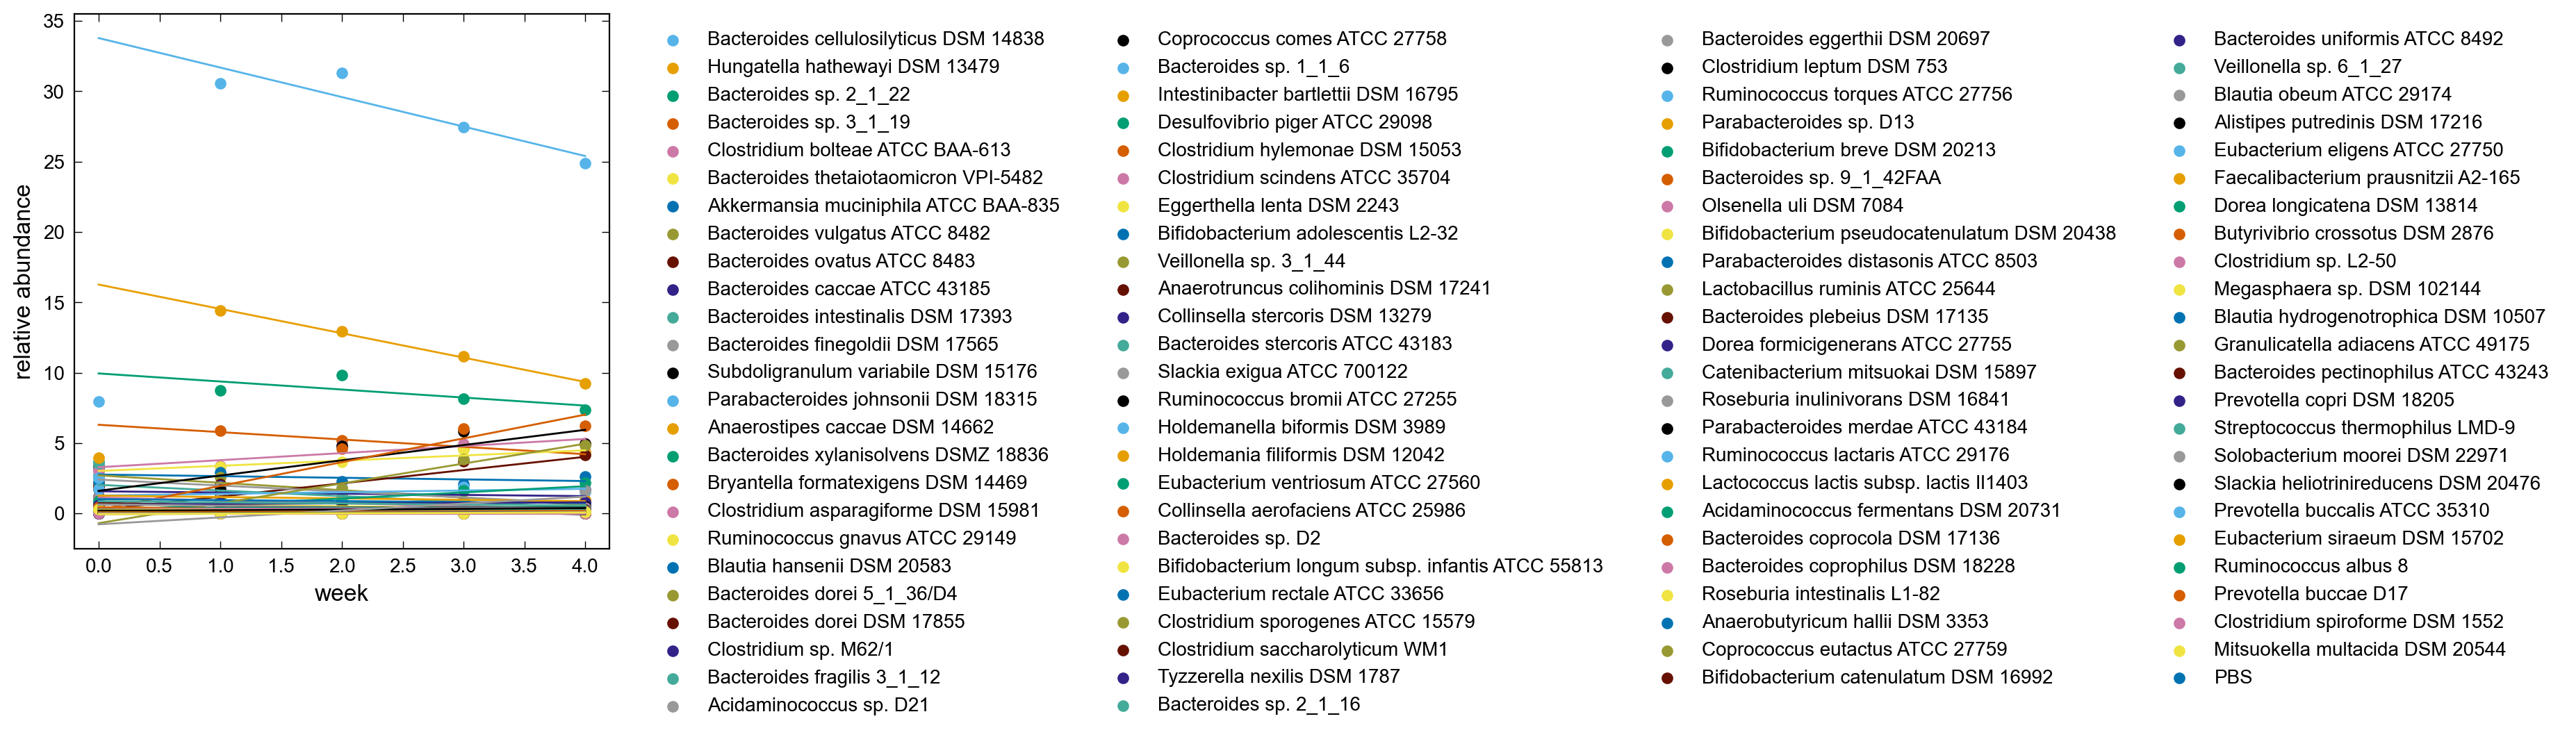

In [7]:
# Using mean data from Wang et al (2023)
fig, ax = plt.subplots(1, 1, figsize=(5.0, 5.0), sharex = False, constrained_layout=True)

var_list = ['day0_abundance', 'wk1_mean_abundance', 'wk2_mean_abundance', 'wk3_mean_abundance', 'wk4_mean_abundance']
strain_list = full_data.loc[full_data.Strain_Name.notna()].sort_values(by='wk1_mean_abundance', ascending= False).Strain_Name

for strain in strain_list:
    #full_data.loc[full_data.alt_Strain_Name == strain].day0_abundance.value
    y_data = full_data.loc[full_data.Strain_Name == strain, var_list].values.ravel().tolist()
    x_data = [0, 1, 2, 3, 4]
    ax.scatter(x_data, y_data, label = strain)
    m, b, r_value, p_value, std_err = scipy.stats.linregress(x_data[1:], y_data[1:])
    ax.plot(np.array(x_data), 
            m*np.array(x_data) + b)

    
ax.legend(bbox_to_anchor=(1.05, 1.0), fontsize=10, framealpha=0, ncol = 4)

ax.set_xlabel('week', fontsize = 12)
ax.set_ylabel('relative abundance', fontsize = 12)
# ax.semilogy()
ax.set_box_aspect(1)
ax.minorticks_off()
ax.tick_params(axis='both', which='major', labelsize=10)
ax.xaxis.set_tick_params(labeltop=False)

Fecal matter data from Wang et al. (2023) has more data points and more reliable trends. We'll use this going forward.

#### Reactivity of individual T-cell receptors to individual hCom1d microbes
This data comes from Figure 3 in Nagashima et al. (2023). Data is only available for a subset of the microbes.

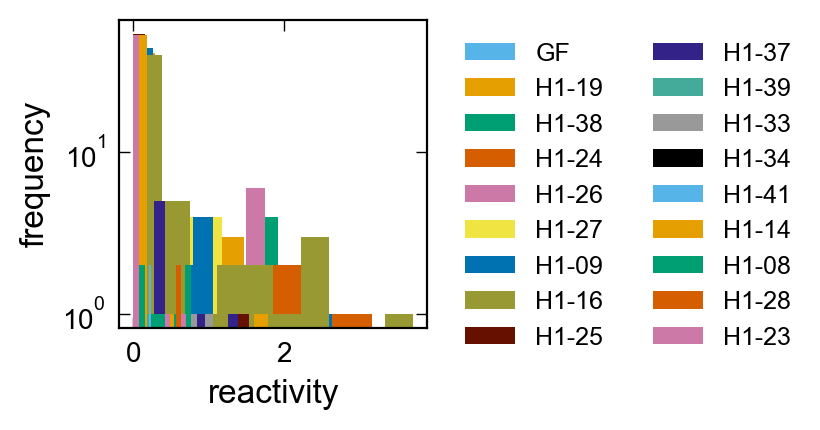

In [8]:
# Plot figures
fig, ax = plt.subplots(1, 1, figsize=(2.0, 2.0), sharex = False, constrained_layout=True)

labels = [['strain abundance', 'frequency'], 
          ['day 0', 'day 2'], ['day 0', 'day 14'], ['day 0', 'day 28'], ['day 14', 'day 28']]
var_list = ['GF',
            'H1-19','H1-38','H1-24','H1-26','H1-27','H1-09','H1-16',
            'H1-25',
            'H1-37','H1-39','H1-33','H1-34',
            'H1-41','H1-14','H1-08',
            'H1-28',
            'H1-23']

for var in var_list:
    ax.hist(pd.to_numeric(cross_reactivity_data[var]), bins = 10, log = True, label = var);

    
ax.legend(bbox_to_anchor=(1.05, 1.0), fontsize=9, framealpha=0, ncol = 2)

ax.set_xlabel('reactivity', fontsize = 12)
ax.set_ylabel('frequency', fontsize = 12)
    
ax.set_box_aspect(1)
ax.minorticks_off()
ax.tick_params(axis='both', which='major', labelsize=10)
ax.xaxis.set_tick_params(labeltop=False)

# plt.savefig('_figs/fig5_'+comment+'-perf_perturb_design'+'.pdf', format="pdf", transparent=True, dpi=300)

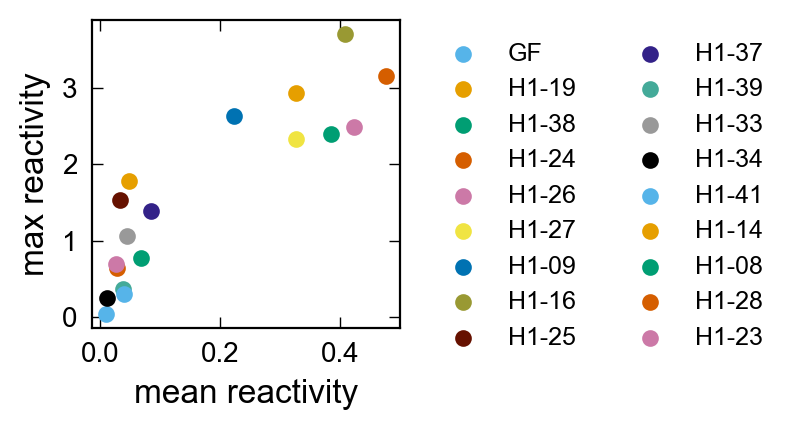

In [9]:
# Plot figures
fig, ax = plt.subplots(1, 1, figsize=(2.0, 2.0), sharex = False, constrained_layout=True)

labels = [['strain abundance', 'frequency'], 
          ['day 0', 'day 2'], ['day 0', 'day 14'], ['day 0', 'day 28'], ['day 14', 'day 28']]
var_list = ['GF',
            'H1-19','H1-38','H1-24','H1-26','H1-27','H1-09','H1-16',
            'H1-25',
            'H1-37','H1-39','H1-33','H1-34',
            'H1-41','H1-14','H1-08',
            'H1-28',
            'H1-23']

for var in var_list:
    ax.scatter(np.mean(pd.to_numeric(cross_reactivity_data[var])), np.max(pd.to_numeric(cross_reactivity_data[var])), label = var);

    
ax.legend(bbox_to_anchor=(1.05, 1.0), fontsize=9, framealpha=0, ncol = 2)

ax.set_xlabel('mean reactivity', fontsize = 12)
ax.set_ylabel('max reactivity', fontsize = 12)
    
ax.set_box_aspect(1)
ax.minorticks_off()
ax.tick_params(axis='both', which='major', labelsize=10)
ax.xaxis.set_tick_params(labeltop=False)

# plt.savefig('_figs/fig5_'+comment+'-perf_perturb_design'+'.pdf', format="pdf", transparent=True, dpi=300)

#### Immune coverage of hCom1d by T-cell repertoire
This data comes from Figure 2 in Nagashima et al. (2023).

In [10]:
# idea: highlight the relative abundance of the microbes. Signal might be clearer for more abundant microbes

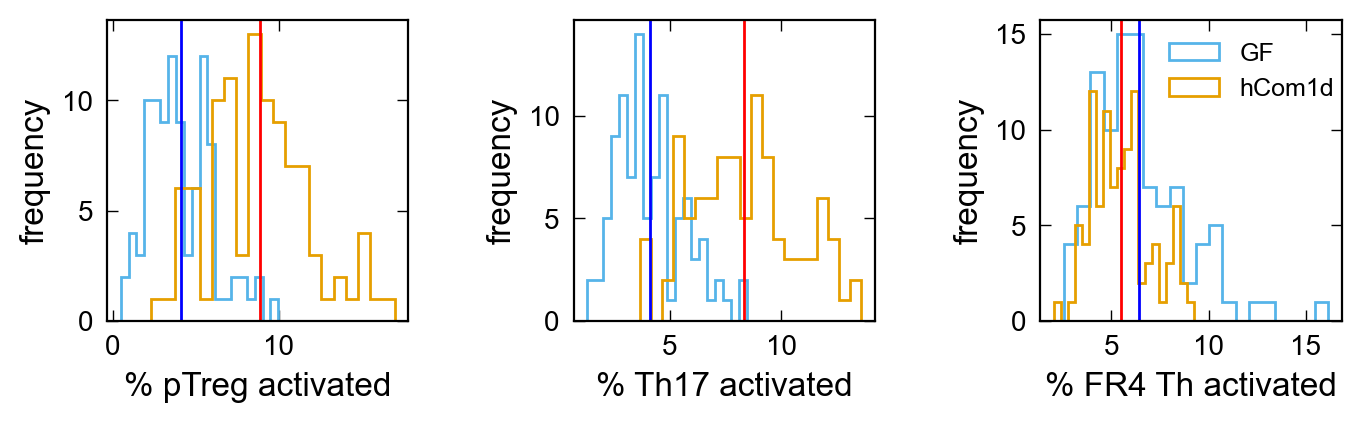

In [11]:
# Plot figures
fig, axs = plt.subplots(1, 3, figsize=(7.0, 2.0), sharex = False, constrained_layout=True)

# labels = 
var_list = [['GF_pTreg_Average', 'hCom1d_pTreg_Average'], 
                      ['GF_Th17_Average', 'hCom1d_Th17_Average'], 
                      ['GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']]

for i, var in enumerate(var_list):
    axs[i].hist(full_data[var[0]], bins = 20, histtype = 'step',label = 'GF');
    axs[i].hist(full_data[var[1]], bins = 20, histtype = 'step',label = 'hCom1d');
    axs[i].axvline(x = np.mean(full_data[var[0]]), color = 'blue')
    axs[i].axvline(x = np.mean(full_data[var[1]]), color = 'red')

    if i == (len(var_list) - 1):
        axs[i].legend(bbox_to_anchor=(1.05, 1.0), fontsize=9, framealpha=0)
    
    axs[i].set_xlabel(['% pTreg activated', '% Th17 activated', '% FR4 Th activated'][i], fontsize = 12)
    axs[i].set_ylabel('frequency', fontsize = 12)
        
    axs[i].set_box_aspect(1)
    axs[i].minorticks_off()
    axs[i].tick_params(axis='both', which='major', labelsize=10)
    axs[i].xaxis.set_tick_params(labeltop=False)

# plt.savefig('_figs/fig5_'+comment+'-perf_perturb_design'+'.pdf', format="pdf", transparent=True, dpi=300)

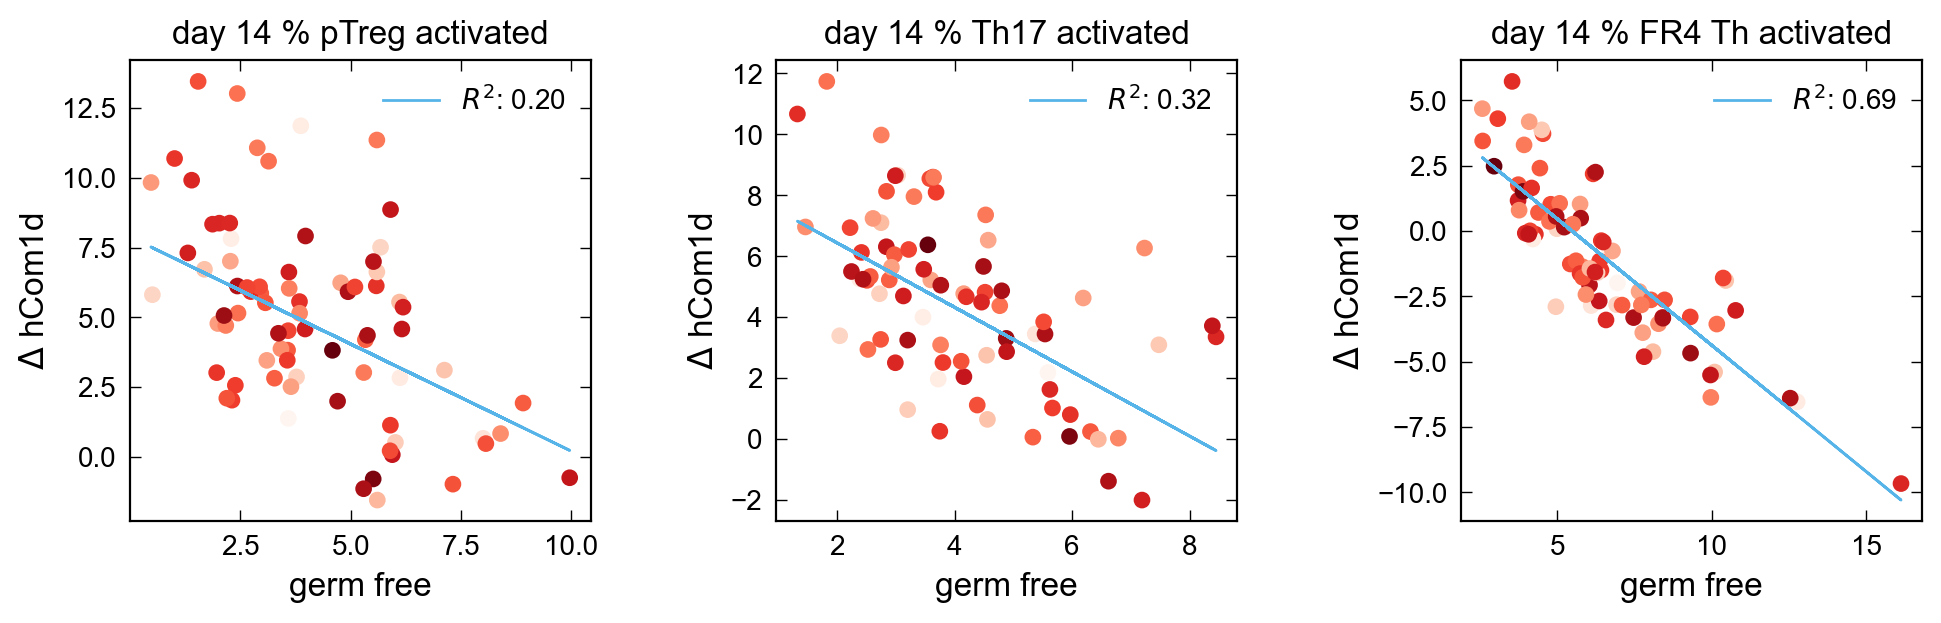

In [12]:
# Plot figures
coverage_variables = ['GF_pTreg_Average', 'hCom1d_pTreg_Average', 
                      'GF_Th17_Average', 'hCom1d_Th17_Average', 
                      'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']

fig, axs = plt.subplots(1, 3, figsize=(10.0, 3.0), sharex = False, constrained_layout=True)

for i, ax in enumerate(axs):

    ax.scatter(full_data[coverage_variables[2*i]], 
               full_data[coverage_variables[2*i + 1]] - full_data[coverage_variables[2*i]],
                c = full_data['day14_abundance'],
               cmap = 'Reds', norm = mpl.colors.LogNorm())
    #ax.plot([0, 15], [0,15])

    m, b, r_value, p_value, std_err = scipy.stats.linregress(full_data[coverage_variables[2*i]], full_data[coverage_variables[2*i + 1]] - full_data[coverage_variables[2*i]])
    ax.plot(full_data[coverage_variables[2*i]], 
            m*full_data[coverage_variables[2*i]] + b, label = r'$R^2$: ' + str("{:.2f}".format(r_value**2)))
    
for j, ax in enumerate(axs.flat):
    ax.legend()
    # ax.semilogx()
    # ax.semilogy()
    ax.set_xlabel('germ free', fontsize = 12)
    ax.set_ylabel(r'$\Delta$ hCom1d', fontsize = 12)
    ax.set_title('day 14 '+['% pTreg activated', '% Th17 activated', '% FR4 Th activated'][j], fontsize = 12)   
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

# plt.savefig('_figs/fig5_'+comment+'-perf_perturb_design'+'.pdf', format="pdf", transparent=True, dpi=300)

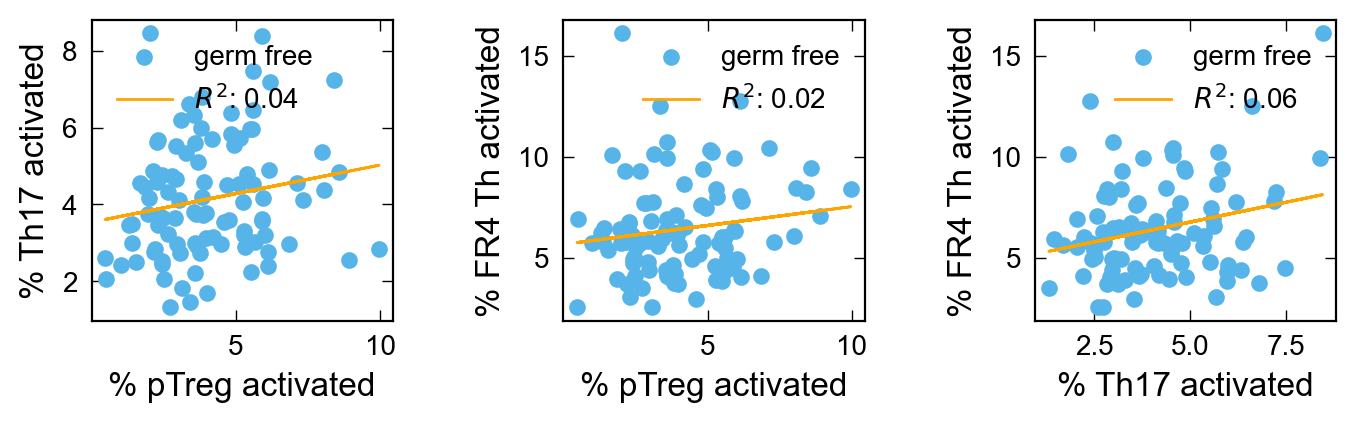

In [13]:
# Plot figures
coverage_variables = ['GF_pTreg_Average', 'hCom1d_pTreg_Average', 
                      'GF_Th17_Average', 'hCom1d_Th17_Average', 
                      'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']
labels = [['% pTreg activated', '% Th17 activated'], ['% pTreg activated', '% FR4 Th activated'], ['% Th17 activated', '% FR4 Th activated']]
var_list = [[coverage_variables[0], coverage_variables[2]],
            [coverage_variables[0], coverage_variables[4]],
            [coverage_variables[2], coverage_variables[4]]]

fig, axs = plt.subplots(1, 3, figsize=(7.0, 2.0), sharex = False, constrained_layout=True)

axs[0].scatter(full_data[coverage_variables[0]], full_data[coverage_variables[2]], marker = 'o', label = 'germ free')
axs[1].scatter(full_data[coverage_variables[0]], full_data[coverage_variables[4]], marker = 'o', label = 'germ free')
axs[2].scatter(full_data[coverage_variables[2]], full_data[coverage_variables[4]], marker = 'o', label = 'germ free')

for i, u in enumerate(var_list):
    m, b, r_value, p_value, std_err = scipy.stats.linregress(full_data[u[0]], full_data[u[1]])
    axs[i].plot(full_data[u[0]], m*full_data[u[0]] + b, color = 'orange', label = r'$R^2$: ' + str("{:.2f}".format(r_value**2)))

for j, ax in enumerate(axs.flat):
    ax.legend()
    # ax.plot([0, 15], [0,15])
    # ax.semilogx()
    # ax.semilogy()
    ax.set_xlabel(labels[j][0], fontsize = 12)
    ax.set_ylabel(labels[j][1], fontsize = 12)
    # ax.set_title(, fontsize = 12)   
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

# plt.savefig('_figs/fig5_'+comment+'-perf_perturb_design'+'.pdf', format="pdf", transparent=True, dpi=300)

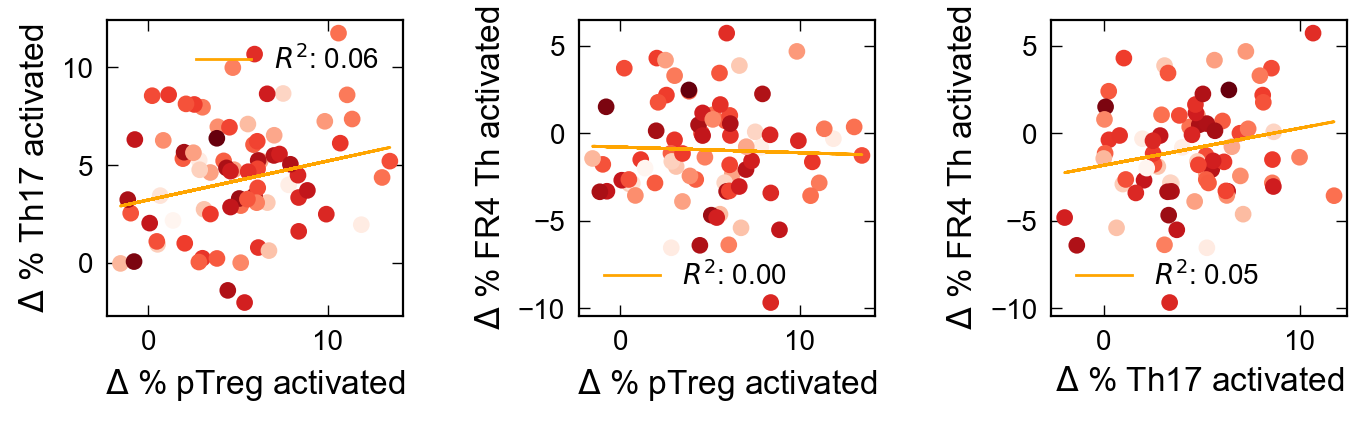

In [14]:
# Plot figures
coverage_variables = ['GF_pTreg_Average', 'hCom1d_pTreg_Average', 
                      'GF_Th17_Average', 'hCom1d_Th17_Average', 
                      'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']
labels = [['% pTreg activated', '% Th17 activated'], ['% pTreg activated', '% FR4 Th activated'], ['% Th17 activated', '% FR4 Th activated']]
var_list = [[1, 3],
            [1, 5],
            [3, 5]]

fig, axs = plt.subplots(1, 3, figsize=(7.0, 2.0), sharex = False, constrained_layout=True)

# axs[0].scatter(full_data[coverage_variables[1]] - full_data[coverage_variables[0]], full_data[coverage_variables[3]] - full_data[coverage_variables[2]], marker = 's', label = 'hCom1d')
# axs[1].scatter(full_data[coverage_variables[1]] - full_data[coverage_variables[0]], full_data[coverage_variables[5]] - full_data[coverage_variables[4]], marker = 's', label = 'hCom1d')
# axs[2].scatter(full_data[coverage_variables[3]] - full_data[coverage_variables[2]], full_data[coverage_variables[5]] - full_data[coverage_variables[4]], marker = 's', label = 'hCom1d')

for i, u in enumerate(var_list):
    x_data = full_data[coverage_variables[u[0]]] - full_data[coverage_variables[u[0] - 1]]
    y_data = full_data[coverage_variables[u[1]]] - full_data[coverage_variables[u[1] - 1]]
    axs[i].scatter(x_data, y_data, marker = 'o', c = full_data['day14_abundance'],
               cmap = 'Reds', norm = mpl.colors.LogNorm())
    m, b, r_value, p_value, std_err = scipy.stats.linregress(x_data, y_data)
    axs[i].plot(x_data, m*x_data + b, color = 'orange', label = r'$R^2$: ' + str("{:.2f}".format(r_value**2)))

for j, ax in enumerate(axs.flat):
    ax.legend()
    ax.set_xlabel(r'$\Delta$ ' + labels[j][0], fontsize = 12)
    ax.set_ylabel(r'$\Delta$ ' + labels[j][1], fontsize = 12)
    # ax.set_title(, fontsize = 12)   
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

# plt.savefig('_figs/fig5_'+comment+'-perf_perturb_design'+'.pdf', format="pdf", transparent=True, dpi=300)

What if we do these regressions only on the most abundant microbes? Or stratified by abundance level

#### Is there a relationship between microbe abundance and immune coverage?

/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


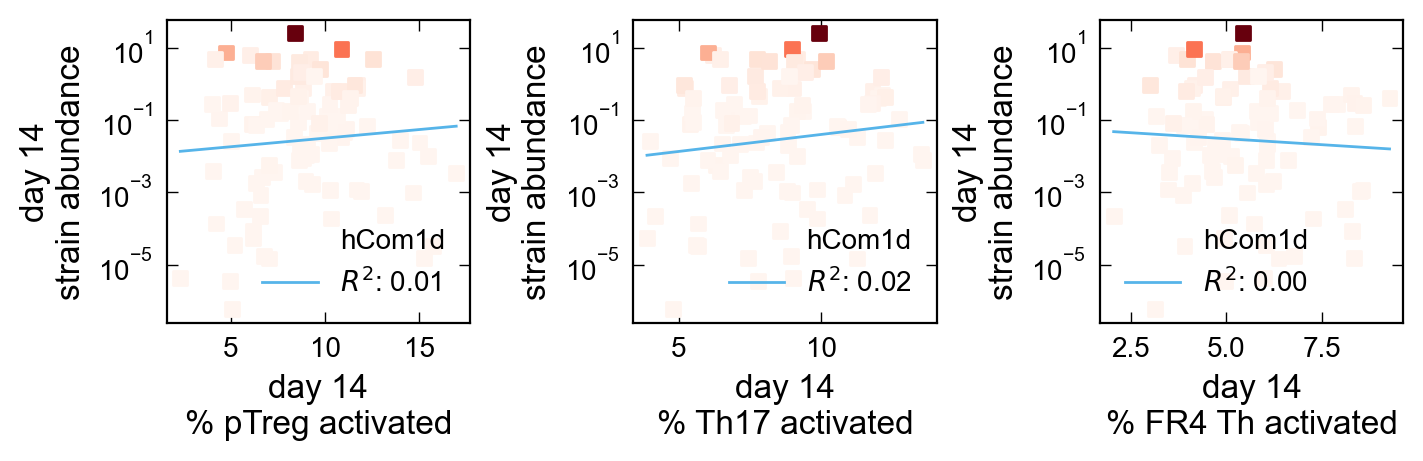

In [15]:
# Plot figures
coverage_variables = ['GF_pTreg_Average', 'hCom1d_pTreg_Average', 
                      'GF_Th17_Average', 'hCom1d_Th17_Average', 
                      'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']

var_list = [coverage_variables[1], coverage_variables[3], coverage_variables[5]]

fig, axs = plt.subplots(1, 3, figsize=(7.0, 2.5), sharex = False, constrained_layout=True)

for i, ax in enumerate(axs):
    x_data = full_data[coverage_variables[2*i + 1]]
    y_data = full_data['wk4_mean_abundance']
    ax.scatter(x_data, 
               y_data, 
               c = full_data['wk1_mean_abundance'],
               cmap = 'Reds',
               marker = 's', label = 'hCom1d')
    mask = ~np.isnan(x_data) & ~np.isnan(y_data) & ~np.isinf(np.log10(y_data))
    m, b, r_value, p_value, std_err = scipy.stats.linregress(x_data[mask], np.log10(y_data[mask]))
    # ax.scatter(x_data[mask], m*x_data[mask] + b)
    ax.plot(np.unique(x_data[mask]), 10**(m*np.unique(x_data[mask]) + b), label = r'$R^2$: ' + str("{:.2f}".format(r_value**2)))

for j, ax in enumerate(axs.flat):
    ax.legend()
    ax.semilogy()
    ax.set_ylabel('day 14\nstrain abundance', fontsize = 12)
    ax.set_xlabel('day 14\n'+['% pTreg activated', '% Th17 activated', '% FR4 Th activated'][j], fontsize = 12)
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

# plt.savefig('_figs/fig5_'+comment+'-perf_perturb_design'+'.pdf', format="pdf", transparent=True, dpi=300)

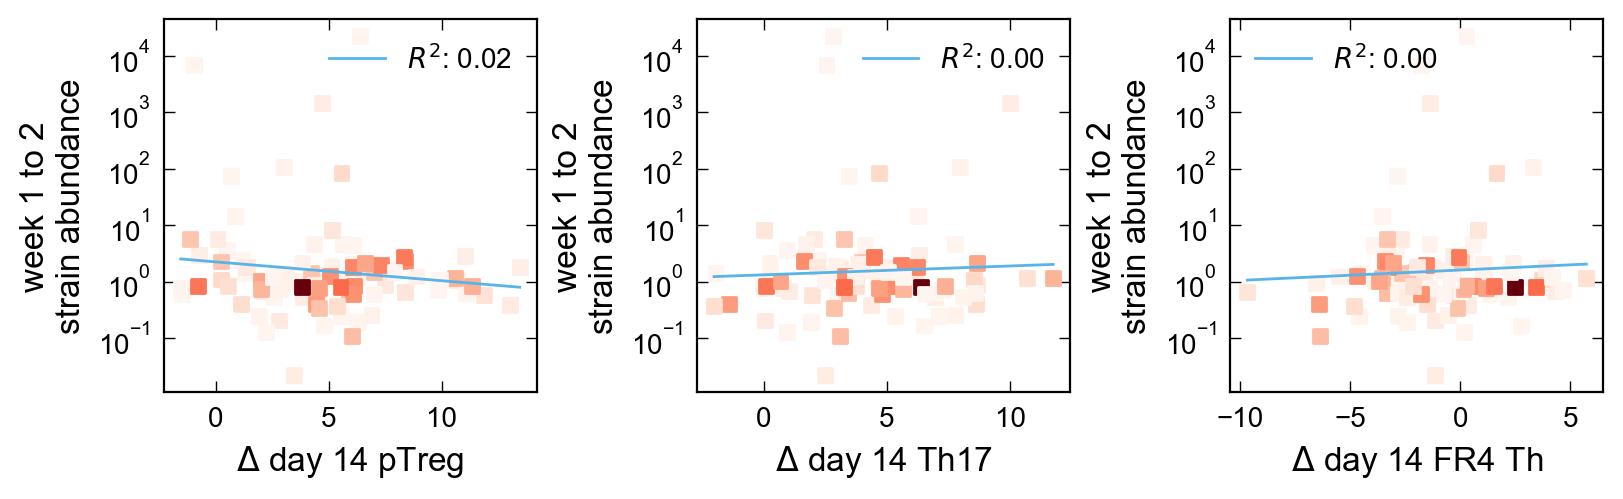

In [16]:
# Plot figures
coverage_variables = ['GF_pTreg_Average', 'hCom1d_pTreg_Average', 
                      'GF_Th17_Average', 'hCom1d_Th17_Average', 
                      'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']

fig, axs = plt.subplots(1, 3, figsize=(8.0, 2.5), sharex = False, constrained_layout=True)

for i, ax in enumerate(axs):
    x_data = full_data[coverage_variables[2*i + 1]] - full_data[coverage_variables[2*i]]
    y_data = full_data['wk4_mean_abundance']/full_data['wk1_mean_abundance']
    ax.scatter(x_data, 
               y_data, 
               c = full_data['day0_abundance'],
               cmap = 'Reds',
               marker = 's')

    mask = ~np.isnan(x_data) & ~np.isnan(y_data) & ~np.isinf(np.log10(y_data))
    m, b, r_value, p_value, std_err = scipy.stats.linregress(x_data[mask], np.log10(y_data[mask]))
    # ax.scatter(x_data[mask], m*x_data[mask] + b)
    ax.plot(np.unique(x_data[mask]), 10**(m*np.unique(x_data[mask]) + b), label = r'$R^2$: ' + str("{:.2f}".format(r_value**2)))

for j, ax in enumerate(axs.flat):
    ax.legend()
    ax.semilogy()
    # ax.semilogx()
    ax.set_ylabel('week 1 to 2\nstrain abundance', fontsize = 12)
    ax.set_xlabel(r'$\Delta$ day 14 '+['pTreg', 'Th17', 'FR4 Th'][j], fontsize = 12)
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

# plt.savefig('_figs/fig5_'+comment+'-perf_perturb_design'+'.pdf', format="pdf", transparent=True, dpi=300)

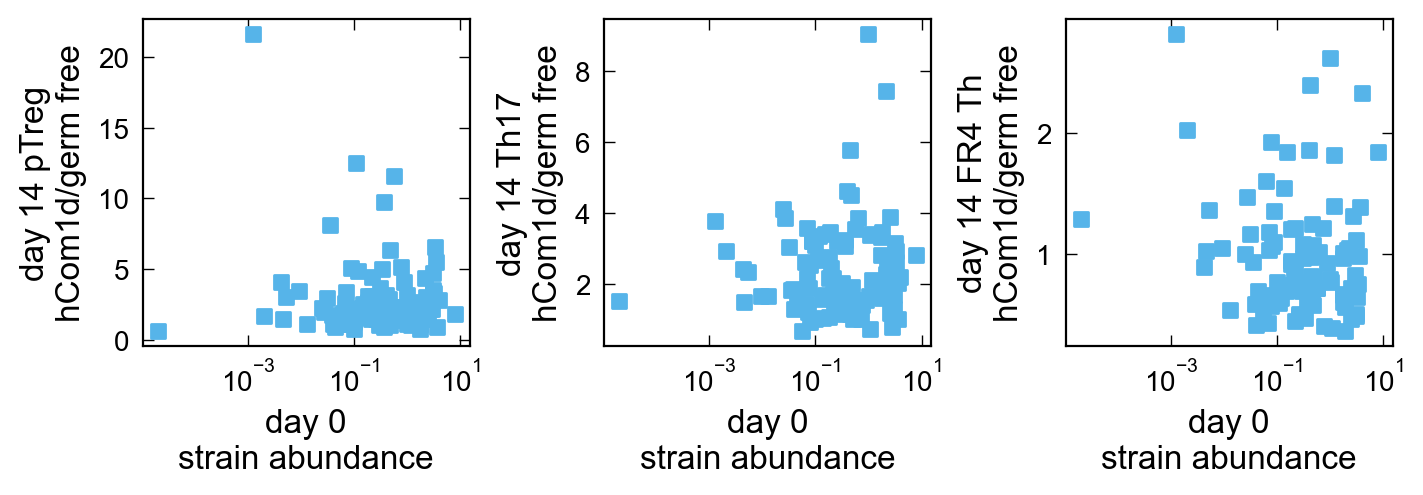

In [17]:
# Plot figures
coverage_variables = ['GF_pTreg_Average', 'hCom1d_pTreg_Average', 
                      'GF_Th17_Average', 'hCom1d_Th17_Average', 
                      'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']

fig, axs = plt.subplots(1, 3, figsize=(7.0, 2.5), sharex = False, constrained_layout=True)

for i, ax in enumerate(axs):
    ax.scatter(full_data['day0_abundance'], 
               full_data[coverage_variables[2*i + 1]]/full_data[coverage_variables[2*i]], marker = 's')

for j, ax in enumerate(axs.flat):
    ax.semilogx()
    ax.set_xlabel('day 0\nstrain abundance', fontsize = 12)
    ax.set_ylabel('day 14 '+['pTreg\nhCom1d/germ free', 'Th17\nhCom1d/germ free', 'FR4 Th\nhCom1d/germ free'][j], fontsize = 12)
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

# plt.savefig('_figs/fig5_'+comment+'-perf_perturb_design'+'.pdf', format="pdf", transparent=True, dpi=300)

In [18]:
# # Build zehn dataset

# # Plot figures
# coverage_variables = ['GF_pTreg_Average', 'hCom1d_pTreg_Average', 
#                       'GF_Th17_Average', 'hCom1d_Th17_Average', 
#                       'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']

# fig, axs = plt.subplots(1, 3, figsize=(7.0, 2.0), sharex = False, constrained_layout=True)

# for i, ax in enumerate(axs):

#     ax.scatter(full_data['day28_abundance'], full_data[coverage_variables[2*i]], marker = 'o', label = 'germ free')
#     ax.scatter(full_data['day28_abundance'], full_data[coverage_variables[2*i + 1]], marker = 's', label = 'hCom1d')
    

# for j, ax in enumerate(axs.flat):
#     ax.legend()
#     ax.semilogx()
#     ax.semilogy()
#     ax.set_xlabel('strain abundance', fontsize = 12)
#     ax.set_ylabel('day 28\n'+['% pTreg activated', '% Th17 activated', '% FR4 Th activated'][j], fontsize = 12)
#     ax.set_box_aspect(1)
#     ax.minorticks_off()
#     ax.tick_params(axis='both', which='major', labelsize=10)
#     ax.xaxis.set_tick_params(labeltop=False)

# # plt.savefig('_figs/fig5_'+comment+'-perf_perturb_design'+'.pdf', format="pdf", transparent=True, dpi=300)

In [19]:
# Compare compositional variance of individual microbes and microbes targeted by the same receptors.
# Hypothesis is that collective abundance of targeted microbes should vary much less than individual abundance
# Contrast this with grouping by Phylum (or other genetic data) and random shuffling
# How can I measure this? Do I have the data?

#### Ecology of the microbial community
Using amino acid dropouts (Cheng et al. (2022)) and strain drop outs (Wang et al. (2023).

/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


[0.82832972 0.12783305 0.04383723]


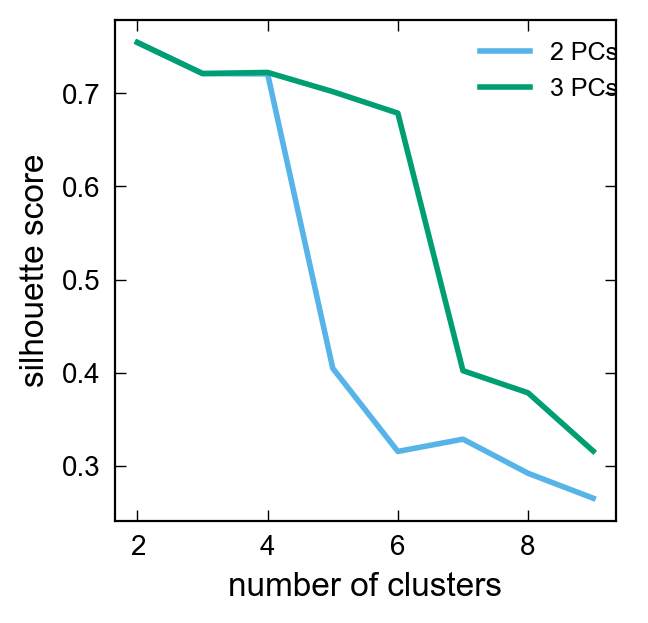

In [20]:
# Cluster based on strain drop outs
fig, axs = plt.subplots(1,1, figsize=(4, 3.0), sharex='row', sharey=False,layout='constrained')

# Scale and center data for clustering
cluster_vars = ['drop_Ch_abundance','drop_Cs_abundance','drop_ChCs_abundance']
input_data = strain_dropout_abundance_data[cluster_vars + ['week3_cecum_abundance']].sort_values(by='week3_cecum_abundance', ascending= False).apply(alr_transform, axis=0).fillna(0)

cluster_input = input_data[cluster_vars].sub(input_data['week3_cecum_abundance'], axis=0)
mask = np.sum(~np.isnan(cluster_input) & ~np.isinf(cluster_input), axis = 1) == len(cluster_vars)
scaler = RobustScaler()
scaler.fit(cluster_input[cluster_vars].values[mask])
# do PCA
pca = PCA(n_components=len(cluster_vars))
pca.fit(cosine_similarity(cluster_input[cluster_vars].values[mask]))
# pca.fit(scaler.transform(cluster_input[cluster_vars].values[mask]))
print(pca.explained_variance_ratio_)
# dataset for clustering

for l in np.arange(2, np.minimum(len(cluster_vars), 7) + 1):
    for_clustering = PCA(n_components=l).fit_transform(scaler.transform(cluster_input[cluster_vars].values[mask]))
    cluster_iter = np.arange(2,10)
    score = []
    # compute scores
    for k in cluster_iter:
        clustering_object = KMeans(n_clusters=k, n_init = 10, random_state=0)
        score += [silhouette_score(cluster_input[cluster_vars].values[mask], clustering_object.fit_predict(for_clustering))]
        
    axs.plot(cluster_iter, score, color = ito_colors[l], label = str(l)+' PCs', linewidth = 2.0)

axs.legend(bbox_to_anchor=(1.05, 1.0), fontsize=9, framealpha=0)
axs.set_xlabel('number of clusters', fontsize = 12)
axs.set_ylabel('silhouette score', fontsize = 12)
axs.set_box_aspect(1)
axs.minorticks_off()
axs.tick_params(axis='both', which='major', labelsize=10)

#plt.savefig('_figs/figSI_'+comment+'-cluster_silhouette_scores'+'.pdf', format="pdf", transparent=True, dpi=300)

[0.43310047 0.31684514 0.0947093  0.06668766 0.03517345 0.02092363
 0.01504084 0.00605924 0.0045863  0.00376338 0.00311059]


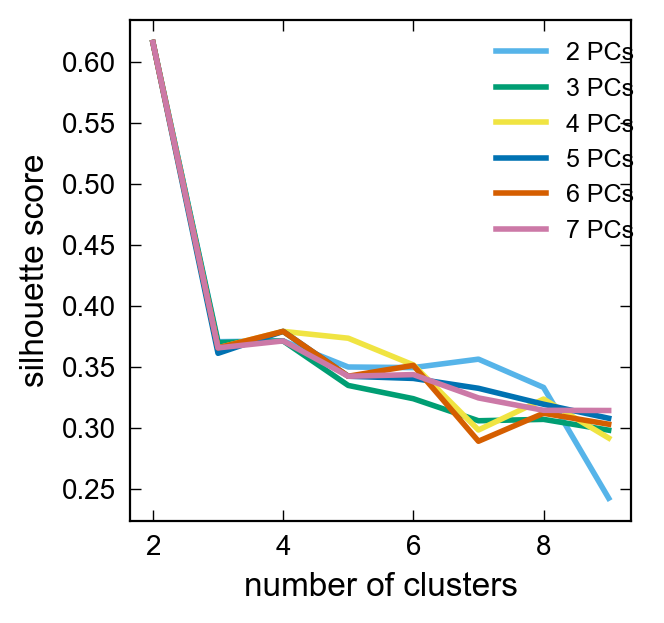

In [21]:
# Cluster based on amino acid drop outs
fig, axs = plt.subplots(1,1, figsize=(4, 3.0), sharex='row', sharey=False,layout='constrained')

# Scale and center data for clustering
cluster_vars = ['Methionine', 'Histidine', 'Isoleucine', 'Arginine', 'Valine',
                'Tyrosine', 'Leucine', 'Serine', 'Tryptophan', 'Proline', 'Glutamine']
# ['Alanine', 'Arginine', 'Asparagine',
#        'AsparticAcid','GlutamicAcid', 'Glutamine', 'Glycine', # removed cysteine
#        'Histidine', 'Isoleucine', 'Leucine', 'Lysine', 'Methionine',
#        'Phenylalanine', 'Proline', 'Serine', 'Threonine', 'Tryptophan',
#        'Tyrosine', 'Valine']

input_data = 10**(amino_dropout_abundance_data[cluster_vars + ['day2_log10_abundance']].sort_values(by='day2_log10_abundance', ascending= False).fillna(-6)).apply(alr_transform, axis=0).fillna(0)

cluster_input = input_data[cluster_vars].sub(input_data['day2_log10_abundance'], axis=0)
mask = np.sum(~np.isnan(cluster_input) & ~np.isinf(cluster_input), axis = 1) == len(cluster_vars)
scaler = RobustScaler()
scaler.fit(cluster_input[cluster_vars].values[mask])
# do PCA
pca = PCA(n_components=len(cluster_vars))
pca.fit(scaler.transform(cluster_input[cluster_vars].values[mask]))
print(pca.explained_variance_ratio_)
# dataset for clustering
for l in np.arange(2, np.minimum(len(cluster_vars), 7) + 1):
    for_clustering = PCA(n_components=l).fit_transform(scaler.transform(cluster_input[cluster_vars].values[mask]))
    cluster_iter = np.arange(2,10)
    score = []
    # compute scores
    for k in cluster_iter:
        clustering_object = KMeans(n_clusters=k, n_init = 10, random_state=0)
        score += [silhouette_score(cluster_input[cluster_vars].values[mask], clustering_object.fit_predict(for_clustering))]
        
    axs.plot(cluster_iter, score, color = ito_colors[l], label = str(l)+' PCs', linewidth = 2.0)

axs.legend(bbox_to_anchor=(1.05, 1.0), fontsize=9, framealpha=0)
axs.set_xlabel('number of clusters', fontsize = 12)
axs.set_ylabel('silhouette score', fontsize = 12)
axs.set_box_aspect(1)
axs.minorticks_off()
axs.tick_params(axis='both', which='major', labelsize=10)

#plt.savefig('_figs/figSI_'+comment+'-cluster_silhouette_scores'+'.pdf', format="pdf", transparent=True, dpi=300)

/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


[5.27211864e-01 1.54870304e-01 1.15653941e-01 8.59143794e-02
 4.79070308e-02 3.60748958e-02 1.85637339e-02 6.06643885e-03
 2.75927428e-03 1.74495129e-03 1.13915612e-03 8.86731638e-04
 6.08815635e-04 4.57211652e-04 1.41272209e-04]


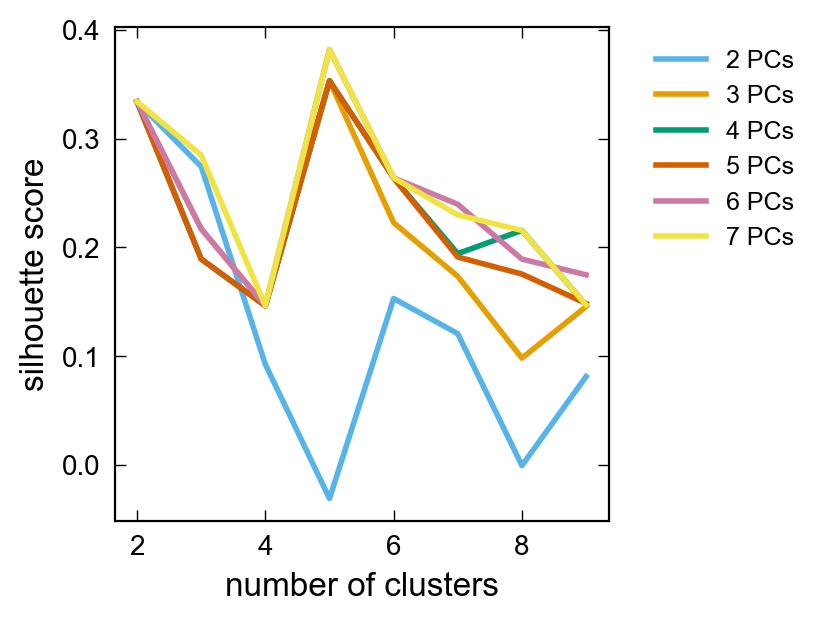

In [22]:
# Cluster based on combined strain and amino acid drop outs
fig, axs = plt.subplots(1,1, figsize=(4, 3.0), sharex='row', sharey=False,layout='constrained')

# Scale and center data for clustering
amino_vars = ['Cysteine','Methionine', 'Histidine', 'Isoleucine', 'Arginine', 'Valine',
                'Tyrosine', 'Leucine', 'Serine', 'Tryptophan', 'Proline', 'Glutamine']
strain_vars = ['drop_Ch_abundance','drop_Cs_abundance','drop_ChCs_abundance']
cluster_vars = amino_vars + strain_vars

input_data = strain_dropout_abundance_data.loc[strain_dropout_abundance_data.strain_id.notna(), strain_vars + ['strain_id','week3_cecum_abundance']].merge(amino_dropout_abundance_data.loc[amino_dropout_abundance_data.strain_id.notna()], 
                                                                                                      how = 'left', on = 'strain_id', validate = 'one_to_one'
                                       ).sort_values(by='week3_cecum_abundance', ascending= False)
input_data[amino_vars + ['day2_log10_abundance']] = 10**(input_data[amino_vars + ['day2_log10_abundance']].fillna(-6)).apply(alr_transform, axis=0).fillna(0)
input_data[strain_vars + ['week3_cecum_abundance']] = input_data[strain_vars + ['week3_cecum_abundance']].apply(alr_transform, axis=0).fillna(0)

cluster_input = pd.concat([input_data[amino_vars].sub(input_data['day2_log10_abundance'], axis=0), 
                               input_data[strain_vars].sub(input_data['week3_cecum_abundance'], axis=0)],
                              axis = 1)
mask = np.sum(~np.isnan(cluster_input) & ~np.isinf(cluster_input), axis = 1) == len(cluster_vars)
scaler = RobustScaler()
scaler.fit(cluster_input[cluster_vars].values[mask])
# do PCA
pca = PCA(n_components=len(cluster_vars))
pca.fit(scaler.transform(cluster_input[cluster_vars].values[mask]))
print(pca.explained_variance_ratio_)
# dataset for clustering
for l in np.arange(2, np.minimum(len(cluster_vars), 7) + 1):
    for_clustering = PCA(n_components=l).fit_transform(scaler.transform(cluster_input[cluster_vars].values[mask]))
    cluster_iter = np.arange(2,10)
    score = []
    # compute scores
    for k in cluster_iter:
        clustering_object = KMeans(n_clusters=k, n_init = 10, random_state=0)
        score += [silhouette_score(cluster_input[cluster_vars].values[mask], clustering_object.fit_predict(for_clustering))]
        
    axs.plot(cluster_iter, score, label = str(l)+' PCs', linewidth = 2.0)

axs.legend(bbox_to_anchor=(1.05, 1.0), fontsize=9, framealpha=0)

axs.set_xlabel('number of clusters', fontsize = 12)
axs.set_ylabel('silhouette score', fontsize = 12)
axs.set_box_aspect(1)
axs.minorticks_off()
axs.tick_params(axis='both', which='major', labelsize=10)

#plt.savefig('_figs/figSI_'+comment+'-cluster_silhouette_scores'+'.pdf', format="pdf", transparent=True, dpi=300)

[0.28042783 0.17463618 0.14137464 0.08553668 0.07610377 0.06312062
 0.05529092 0.04266415 0.02946972 0.02667738 0.00790391 0.00652693
 0.00340968 0.00241826 0.0021046  0.00140918 0.00092555]


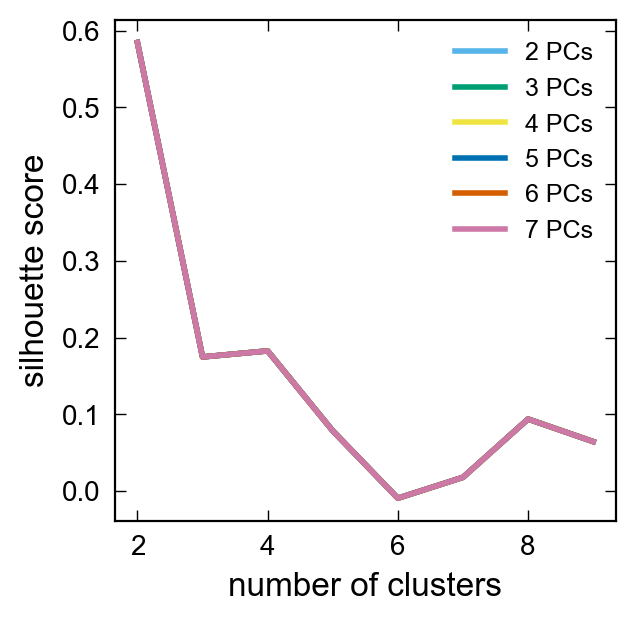

In [48]:
# Cluster based on immune receptor binding
fig, axs = plt.subplots(1,1, figsize=(4, 3.0), sharex='row', sharey=False,layout='constrained')

# Scale and center data for clustering
cluster_vars = ['H1-19','H1-38','H1-24','H1-26','H1-27','H1-09','H1-16',
            'H1-25',
            'H1-37','H1-39','H1-33','H1-34',
            'H1-41','H1-14','H1-08',
            'H1-28',
            'H1-23']

#cluster_input = np.log10(cross_reactivity_data[cluster_vars]/np.mean(cross_reactivity_data['GF'])).replace([-np.inf], 0.0)
cluster_input = cross_reactivity_data[cluster_vars]# - np.mean(cross_reactivity_data['GF'])
mask = np.sum(~np.isnan(cluster_input) & ~np.isinf(cluster_input), axis = 1) == len(cluster_vars)
# scaler = RobustScaler()
# scaler.fit(cluster_input[cluster_vars].values[mask])
normalizer = Normalizer(norm='l2')
cluster_input_norm = normalizer.fit_transform(cluster_input[cluster_vars].values[mask])
# do PCA
pca = PCA(n_components=len(cluster_vars))
pca.fit(cluster_input_norm)
#pca.fit(cosine_similarity(cluster_input[cluster_vars].values[mask]))
print(pca.explained_variance_ratio_)
# dataset for clustering
for l in np.arange(2, np.minimum(len(cluster_vars), 7) + 1):
    for_clustering = cluster_input_norm #PCA(n_components=l).fit_transform(cluster_input_norm)
    #for_clustering = PCA(n_components=l).fit_transform(cosine_similarity(cluster_input[cluster_vars].values[mask]))
    cluster_iter = np.arange(2,10)
    score = []
    # compute scores
    for k in cluster_iter:
        clustering_object = KMeans(n_clusters=k, n_init = 10, random_state=0)
        score += [silhouette_score(cluster_input[cluster_vars].values[mask], clustering_object.fit_predict(for_clustering))]
        
    axs.plot(cluster_iter, score, color = ito_colors[l], label = str(l)+' PCs', linewidth = 2.0)

axs.legend(fontsize=9, framealpha=0)
axs.set_xlabel('number of clusters', fontsize = 12)
axs.set_ylabel('silhouette score', fontsize = 12)
axs.set_box_aspect(1)
axs.minorticks_off()
axs.tick_params(axis='both', which='major', labelsize=10)

#plt.savefig('_figs/figSI_'+comment+'-cluster_silhouette_scores'+'.pdf', format="pdf", transparent=True, dpi=300)

/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


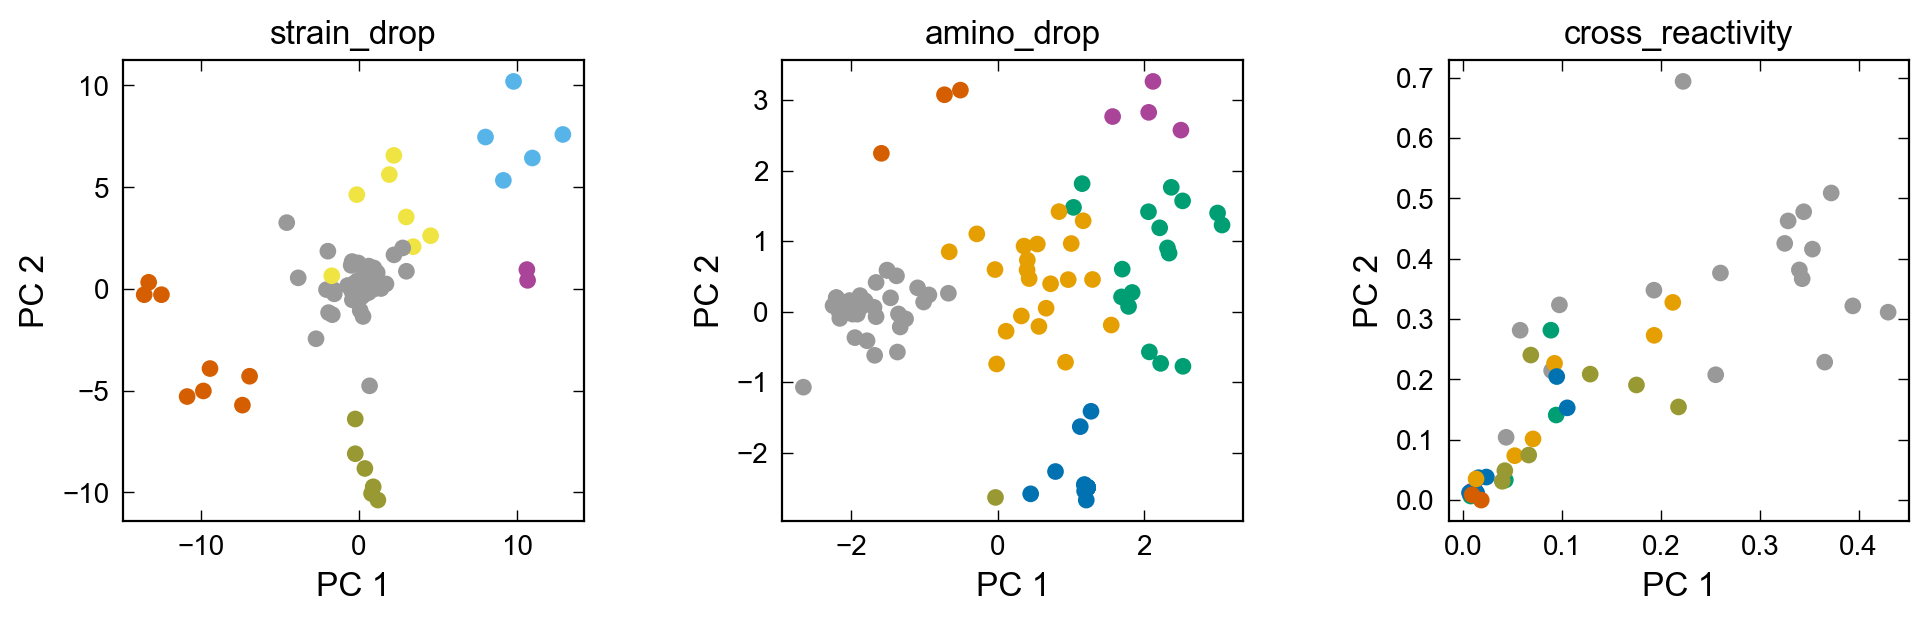

In [54]:
df_list = [strain_dropout_abundance_data, amino_dropout_abundance_data, cross_reactivity_data.loc[cross_reactivity_data.strain_id.notna()].merge(full_data.loc[full_data.strain_id.notna(),['strain_id', 'imm_resp_flag', 'sig_imm_resp_flag']], 
                                                                                                    how = 'left', on = 'strain_id', validate = 'one_to_one')]
cluster_vars_list = [['drop_Ch_abundance','drop_Cs_abundance', 'drop_ChCs_abundance'],
                     ['Cysteine', 'Methionine', 'Histidine', 'Isoleucine', 'Arginine', 'Valine',
                'Tyrosine', 'Leucine', 'Serine', 'Tryptophan', 'Proline', 'Glutamine'],
                     ['H1-19','H1-38','H1-24','H1-26','H1-27','H1-09','H1-16',
                      'H1-25',
                      'H1-37','H1-39','H1-33','H1-34',
                      'H1-41','H1-14','H1-08',
                      'H1-28',
                      'H1-23']]
reference_vars_list = ['week3_cecum_abundance', 'day2_log10_abundance','GF']
label_list = ['strain_drop','amino_drop','cross_reactivity']
cluster_num_list = [6,7,7]
pca_num_list = [3,3,4]
full_data_w_clusters = full_data.loc[full_data.strain_id.notna()*full_data.Phyla.notna()]

fig, axs = plt.subplots(1, 3, figsize=(10.0, 3.0), sharex = False, constrained_layout=True)


for i, df in enumerate(df_list):
    if i == 0:
        input_data = df[cluster_vars_list[i] + [reference_vars_list[i]]].sort_values(by=reference_vars_list[i], ascending= False).apply(alr_transform, axis=0).fillna(0).replace([-np.inf], 0.0)
        scaler = RobustScaler()
        cluster_input = input_data[cluster_vars_list[i]].sub(input_data[reference_vars_list[i]], axis=0)
        mask = np.sum(~np.isnan(cluster_input) & ~np.isinf(cluster_input), axis = 1) == len(cluster_vars_list[i])
        scaler.fit(cluster_input[cluster_vars_list[i]].values[mask])
        for_clustering = scaler.transform(cluster_input[cluster_vars_list[i]].values[mask])
    elif i == 1:
        input_data = 10**(df[cluster_vars_list[i] + [reference_vars_list[i]]].fillna(-6)).sort_values(by=reference_vars_list[i], ascending= False).apply(alr_transform, axis=0).fillna(0).replace([-np.inf], 0.0)
        scaler = RobustScaler()
        cluster_input = input_data[cluster_vars_list[i]].sub(input_data[reference_vars_list[i]], axis=0)
        mask = np.sum(~np.isnan(cluster_input) & ~np.isinf(cluster_input), axis = 1) == len(cluster_vars_list[i])
        scaler.fit(cluster_input[cluster_vars_list[i]].values[mask])
        for_clustering = PCA(n_components=pca_num_list[i]).fit_transform(scaler.transform(cluster_input[cluster_vars_list[i]].values[mask]))
    else:
        input_data = df[cluster_vars_list[i] + [reference_vars_list[i]]]
        normalizer = Normalizer(norm='l2')
        cluster_input = input_data[cluster_vars_list[i]]
        mask = np.sum(~np.isnan(cluster_input) & ~np.isinf(cluster_input), axis = 1) == len(cluster_vars_list[i])
        cluster_input_norm = normalizer.fit_transform(cluster_input[cluster_vars].values[mask])
        for_clustering = cluster_input_norm #PCA(n_components=pca_num_list[i]).fit_transform(scaler.transform(cluster_input[cluster_vars_list[i]].values[mask]))

    cluster_input['strain_id'] = df.sort_values(by=reference_vars_list[i], ascending= False)['strain_id'] 
    clustering_object = KMeans(n_clusters=cluster_num_list[i], n_init = 10, random_state=0)
    clustering = clustering_object.fit(for_clustering)
    cluster_input.loc[mask,label_list[i]+'_cluster'] = (clustering.labels_ + 1).astype('int64')
    full_data_w_clusters = full_data_w_clusters.merge(cluster_input.loc[cluster_input.strain_id.notna(),['strain_id', label_list[i]+'_cluster'] + (cluster_vars_list[i] if i == 0 else [])], 
                               how = 'left', on = 'strain_id', validate = 'one_to_one')

    full_data_w_clusters.loc[:,label_list[i]+'_cluster'] = full_data_w_clusters[label_list[i]+'_cluster'].fillna(0).astype('int64')

    # Make plots
    axs[i].scatter(for_clustering[:,0], for_clustering[:,1],
                c = clustering.labels_,
              cmap = custom_cmap_discrete)

for j, ax in enumerate(axs.flat):
    ax.set_xlabel(r'PC 1', fontsize = 12)
    ax.set_ylabel(r'PC 2', fontsize = 12)
    ax.set_title(label_list[j], fontsize = 12)   
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

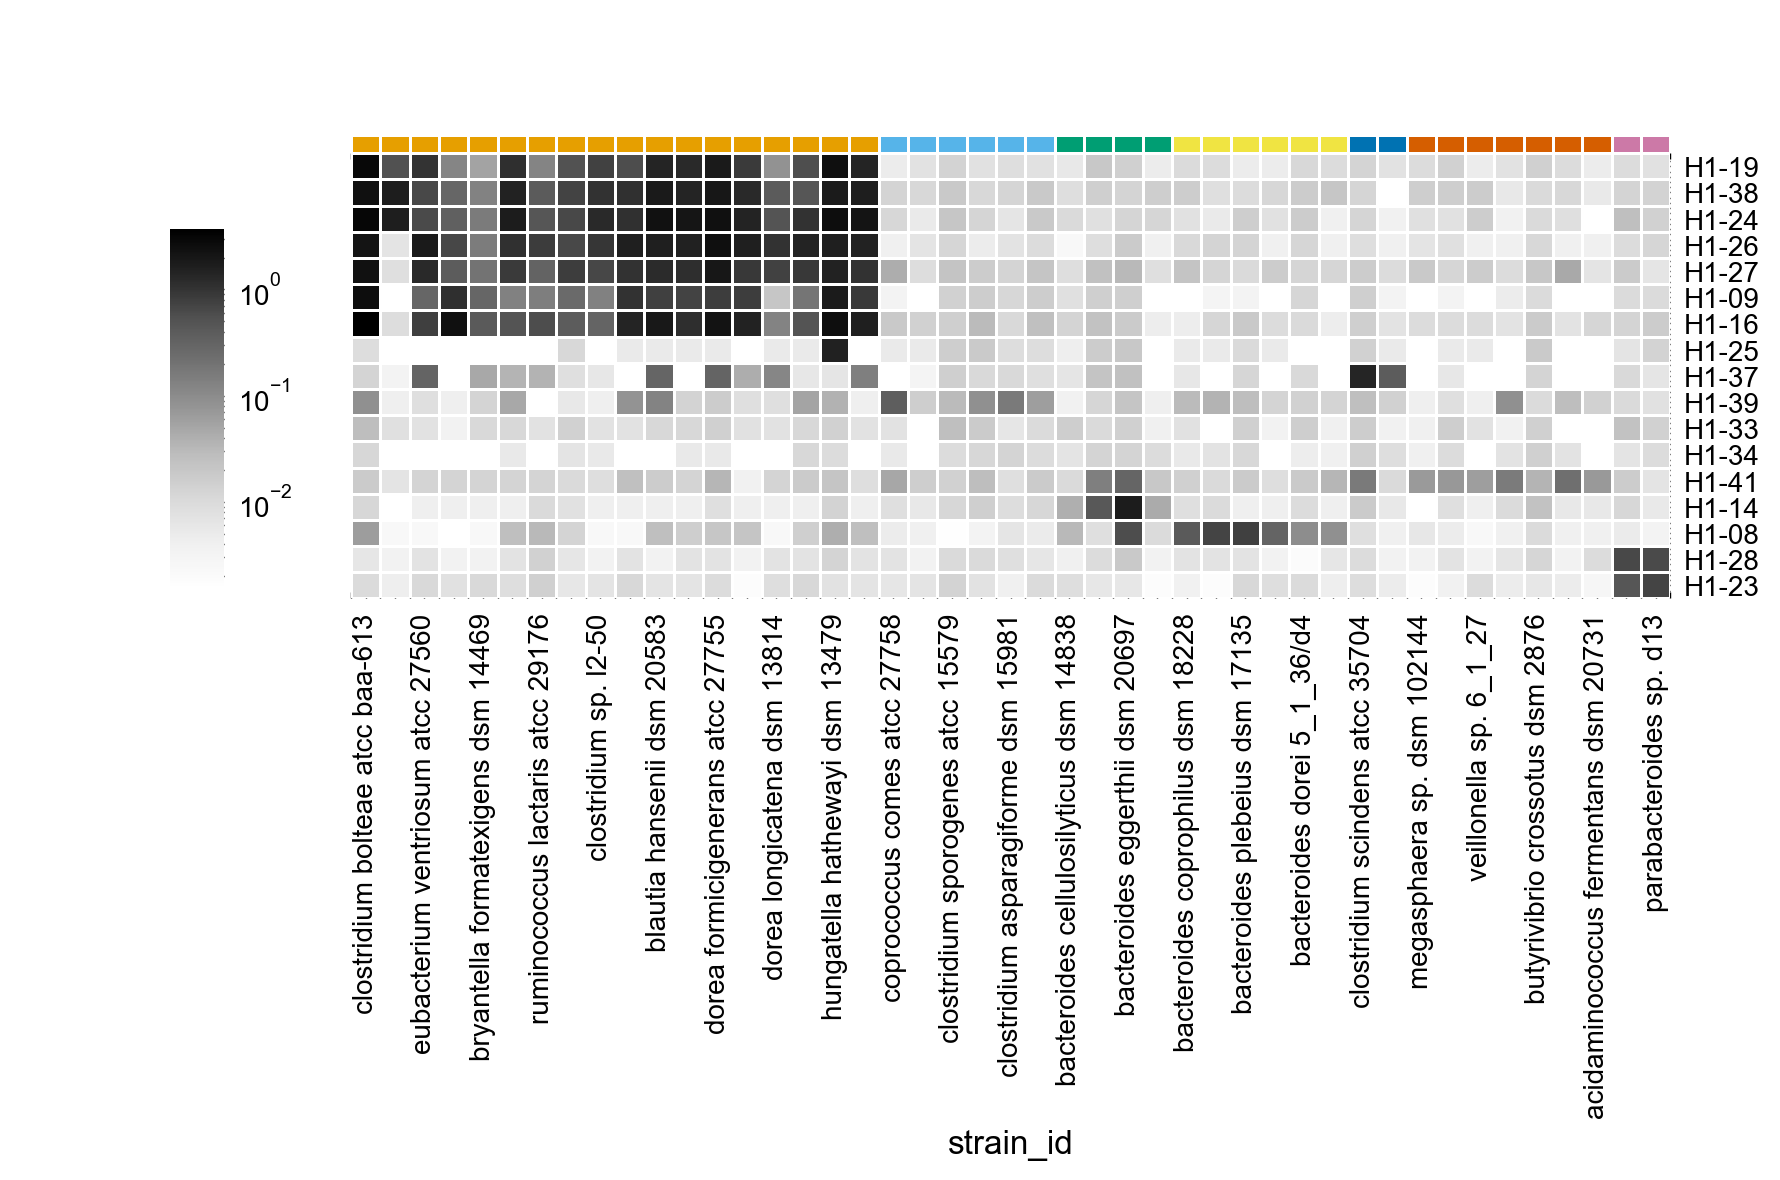

In [72]:
receptor_bind_vars = ['H1-19','H1-38','H1-24','H1-26','H1-27','H1-09','H1-16',
            'H1-25',
            'H1-37','H1-39','H1-33','H1-34',
            'H1-41','H1-14','H1-08',
            'H1-28',
            'H1-23']

input_data = cross_reactivity_data.loc[cross_reactivity_data.strain_id.notna()].merge(full_data_w_clusters[['strain_id', 'imm_resp_flag', 'sig_imm_resp_flag', 'cross_reactivity_cluster']], 
                                                                                                    how = 'left', on = 'strain_id', validate = 'one_to_one').sort_values(by='cross_reactivity_cluster', 
                                                                                                                            ascending= True).set_index('strain_id') 
plot_data = input_data[receptor_bind_vars]

lut = {1: ito_colors[1], 2: ito_colors[2], 3: ito_colors[3], 4: ito_colors[4], 5: ito_colors[5], 6: ito_colors[6], 7: ito_colors[7], 8: ito_colors[8]}
col_colors = input_data['cross_reactivity_cluster'].map(lut)
ax = sns.clustermap(plot_data.transpose(), col_colors=col_colors.values, row_cluster=False, col_cluster=False,
              norm=mpl.colors.LogNorm(), cmap='Greys', fmt=".2f", linewidths=.5,
              cbar_pos=(0.1, .5, .03, .3), figsize=(9, 6))

# The 'fig' object is accessible via the .figure attribute
fig = ax.figure

plt.show()

# To save the figure, use the savefig method of the ClusterGrid object to avoid clipping
ax.savefig('_figs/fig_receptor_clusters'+'.png', dpi=300, bbox_inches='tight')

/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/anaco

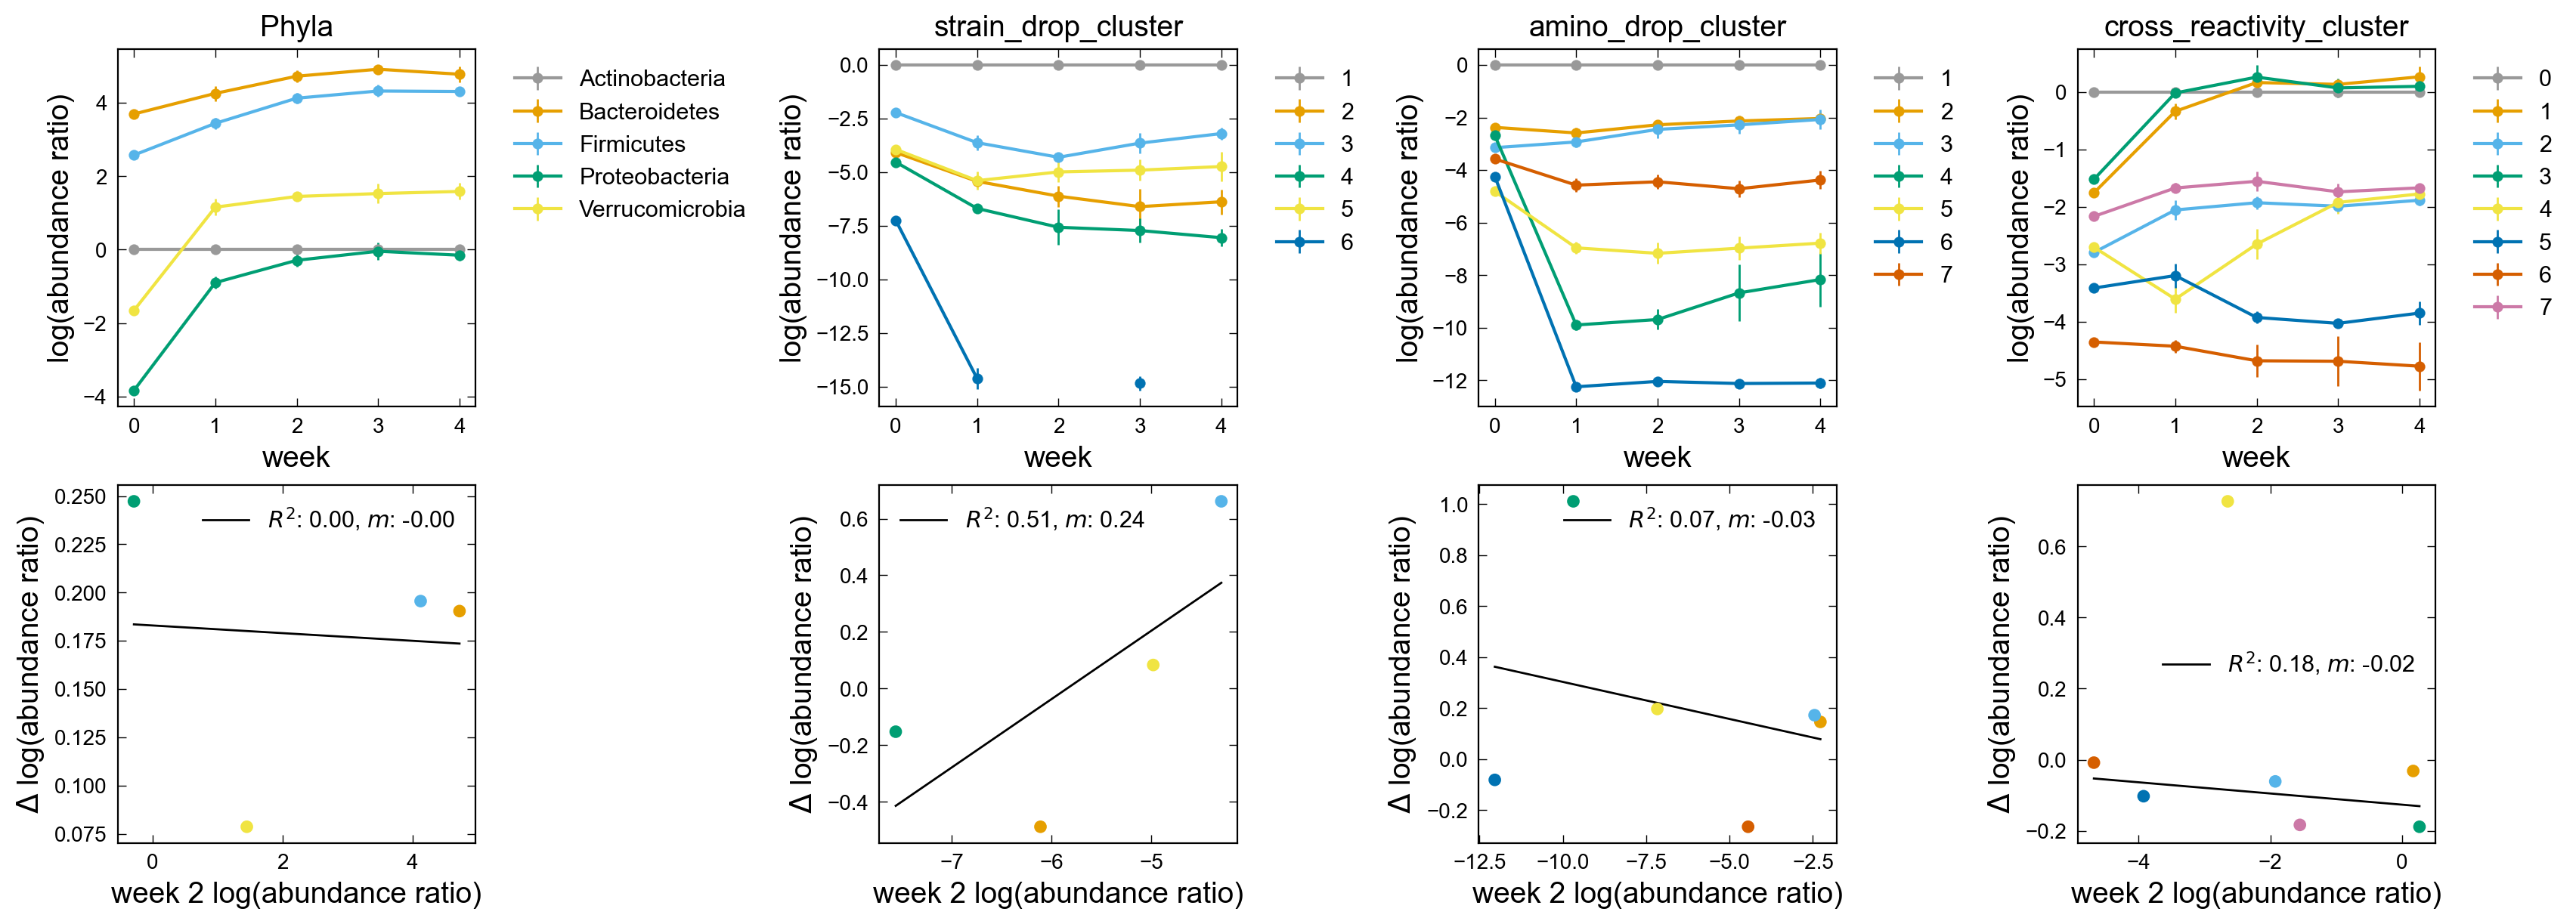

In [73]:
# Plot figures
coverage_variables = ['GF_pTreg_Average', 'hCom1d_pTreg_Average', 
                      'GF_Th17_Average', 'hCom1d_Th17_Average', 
                      'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']
cluster_variables= ['Phyla','strain_drop_cluster','amino_drop_cluster','cross_reactivity_cluster']
var_list = ['day0_abundance','Batch1_week1_m1',
       'Batch1_week1_m2', 'Batch1_week1_m3', 'Batch1_week1_m4',
       'Batch1_week1_m5', 'Batch1_week2_m1', 'Batch1_week2_m2',
       'Batch1_week2_m3', 'Batch1_week2_m4', 'Batch1_week2_m5',
       'Batch1_week3_m1', 'Batch1_week3_m2', 'Batch1_week3_m3',
       'Batch1_week3_m4', 'Batch1_week3_m5', 'Batch1_week4_m1',
       'Batch1_week4_m2', 'Batch1_week4_m3', 'Batch1_week4_m4',
       'Batch1_week4_m5', 'Batch2_week4_m1', 'Batch2_week4_m2',
       'Batch2_week4_m3', 'Batch3_week4_m1', 'Batch3_week4_m2',
       'Batch3_week4_m3', 'Batch3_week4_m4', 'Batch3_week4_m5']

fig, axs = plt.subplots(2, 4, figsize=(17.0, 6.0), sharex = False, constrained_layout=True)

for i, custer_var in enumerate(cluster_variables):
    data = full_data_w_clusters[var_list + coverage_variables + [cluster_variables[i]]].groupby(cluster_variables[i], as_index = False).sum()

    # Compute mean abundance
    data[var_list] = data[var_list].apply(alr_transform, axis=0)
    data.loc[:, 'wk1_mean_abundance'] = np.mean(data[['Batch1_week1_m1','Batch1_week1_m2', 'Batch1_week1_m3', 
                                                                                 'Batch1_week1_m4','Batch1_week1_m5']], axis = 1)
    data.loc[:, 'wk2_mean_abundance'] = np.mean(data[['Batch1_week2_m1', 'Batch1_week2_m2','Batch1_week2_m3', 
                                                                                 'Batch1_week2_m4', 'Batch1_week2_m5']], axis = 1)
    data.loc[:, 'wk3_mean_abundance'] = np.mean(data[['Batch1_week3_m1', 'Batch1_week3_m2', 'Batch1_week3_m3', 
                                                                                 'Batch1_week3_m4', 'Batch1_week3_m5']], axis = 1)
    data.loc[:, 'wk4_mean_abundance'] = np.mean(data[['Batch1_week4_m1','Batch1_week4_m2', 'Batch1_week4_m3', 'Batch1_week4_m4',
                                                                                 'Batch1_week4_m5']], axis = 1)
    
    # Compute standard deviation of abundance
    data.loc[:, 'wk0_std_abundance'] = 0*np.std(data.day0_abundance)
    data.loc[:, 'wk1_std_abundance'] = np.std(data[['Batch1_week1_m1','Batch1_week1_m2', 'Batch1_week1_m3', 
                                                                                 'Batch1_week1_m4','Batch1_week1_m5']], axis = 1)
    data.loc[:, 'wk2_std_abundance'] = np.std(data[['Batch1_week2_m1', 'Batch1_week2_m2','Batch1_week2_m3', 
                                                                                 'Batch1_week2_m4', 'Batch1_week2_m5']], axis = 1)
    data.loc[:, 'wk3_std_abundance'] = np.std(data[['Batch1_week3_m1', 'Batch1_week3_m2', 'Batch1_week3_m3', 
                                                                                 'Batch1_week3_m4', 'Batch1_week3_m5']], axis = 1)
    data.loc[:, 'wk4_std_abundance'] = np.std(data[['Batch1_week4_m1','Batch1_week4_m2', 'Batch1_week4_m3', 'Batch1_week4_m4',
                                                                                 'Batch1_week4_m5']], axis = 1)

    mean_array = data[[cluster_variables[i], 'day0_abundance', 'wk1_mean_abundance', 'wk2_mean_abundance','wk3_mean_abundance','wk4_mean_abundance']].values
    std_array = data[[cluster_variables[i], 'wk0_std_abundance','wk1_std_abundance', 'wk2_std_abundance','wk3_std_abundance','wk4_std_abundance']].values
    x_data = np.array([0, 1, 2, 3, 4])
    
    for k, y in enumerate(mean_array):
        axs[0,i].errorbar(x_data, y[1:],
                    yerr = std_array[k,1:],elinewidth = 1.0,linewidth = 1.5,fmt = '-o', color = ito_colors[k], 
                          label = int(y[0]) if i > 0 else y[0])

    for_analysis = data
    for_analysis.loc[:, 'max_abundance'] = for_analysis['wk2_mean_abundance']
    for_analysis.loc[:, 'del_abundance'] = for_analysis['wk3_mean_abundance'] - for_analysis['wk2_mean_abundance']
    # for_analysis.loc[:, 'del_abundance'] = 10**(-(for_analysis['wk3_mean_abundance'] - for_analysis['wk2_mean_abundance'])) #- 1
    for_analysis.loc[:, 'del_pTreg'] = for_analysis['hCom1d_pTreg_Average'] - for_analysis['GF_pTreg_Average']
    for_analysis.loc[:, 'del_Th17'] = for_analysis['hCom1d_Th17_Average'] - for_analysis['GF_Th17_Average']
    for_analysis.loc[:, 'del_FR4_Th'] = for_analysis['hCom1d_FR4_Th_Average'] - for_analysis['GF_FR4_Th_Average']
    for_analysis.loc[:, 'ratio_pTreg'] = np.log10(for_analysis['hCom1d_pTreg_Average']/for_analysis['GF_pTreg_Average'])
    for_analysis.loc[:, 'ratio_Th17'] = np.log10(for_analysis['hCom1d_Th17_Average']/for_analysis['GF_Th17_Average'])
    for_analysis.loc[:, 'ratio_FR4_Th'] = np.log10(for_analysis['hCom1d_FR4_Th_Average']/for_analysis['GF_FR4_Th_Average'])
    for_analysis.loc[:, 'diff_Th17_pTreg'] = for_analysis['del_Th17'] - for_analysis['del_pTreg']
    for_analysis.loc[:, 'ratio_Th17_pTreg'] = np.log10(for_analysis['del_Th17']/for_analysis['del_pTreg'])
    for_analysis.loc[:, 'ratio_FR4_Th_pTreg'] = np.log10(for_analysis['del_FR4_Th']/for_analysis['del_pTreg'])

    x_data = for_analysis.wk2_mean_abundance.values[1:]
    y_data = for_analysis.del_abundance.values[1:]
    axs[1,i].scatter(x_data, y_data, color = ito_colors[1:1+len(x_data)])

    if i < 3:
        mask = ~np.isnan(x_data) & ~np.isinf(x_data) & ~np.isnan(y_data) & ~np.isinf(y_data)
    else:
        mask = ~np.isnan(x_data) & ~np.isinf(x_data) & ~np.isnan(y_data) & ~np.isinf(y_data) & (y_data <= 0)
    if np.sum(mask) >= 2:
        reg = LinearRegression().fit(x_data[mask].reshape(-1, 1), y_data[mask]) #, sample_weight = z_data)
        r_sq = reg.score(x_data[mask].reshape(-1, 1), y_data[mask]) #, sample_weight = z_data)
        m = reg.coef_[0]
        b = reg.intercept_
        #m, b, r_value, p_value, std_err = scipy.stats.linregress(x_data[mask], y_data[mask])
        axs[1,i].plot(np.unique(x_data[mask]), 
                m*np.unique(x_data[mask]) + b, 
                      color = 'black',
                      zorder = 0,
                label = r'$R^2$: ' + str("{:.2f}".format(r_sq))+ r', $m$: ' + str("{:.2f}".format(m)))
    
for j, ax in enumerate(axs.flat):
    # ax.set_yscale('symlog', linthresh=1.)

    if j < len(cluster_variables):
        ax.set_xlabel('week', fontsize = 14)
        ax.set_ylabel('log(abundance ratio)', fontsize = 14)
        ax.set_title(cluster_variables[j], fontsize = 14)
        ax.legend(bbox_to_anchor=(1.05, 1.0), fontsize=11, framealpha=0)
    else:
        ax.set_xlabel('week 2 log(abundance ratio)', fontsize = 14)
        ax.set_ylabel(r'$\Delta$'+' log(abundance ratio)', fontsize = 14)
        ax.legend(fontsize=11, framealpha=0)
        
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

fig.savefig('_figs/fig_dynamics_by_cluster'+'.png', dpi=300, bbox_inches='tight')

/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_97596/4136812559.py:91: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(bbox_to_anchor=(1.05, 1.0), fontsize=9, framealpha=0)


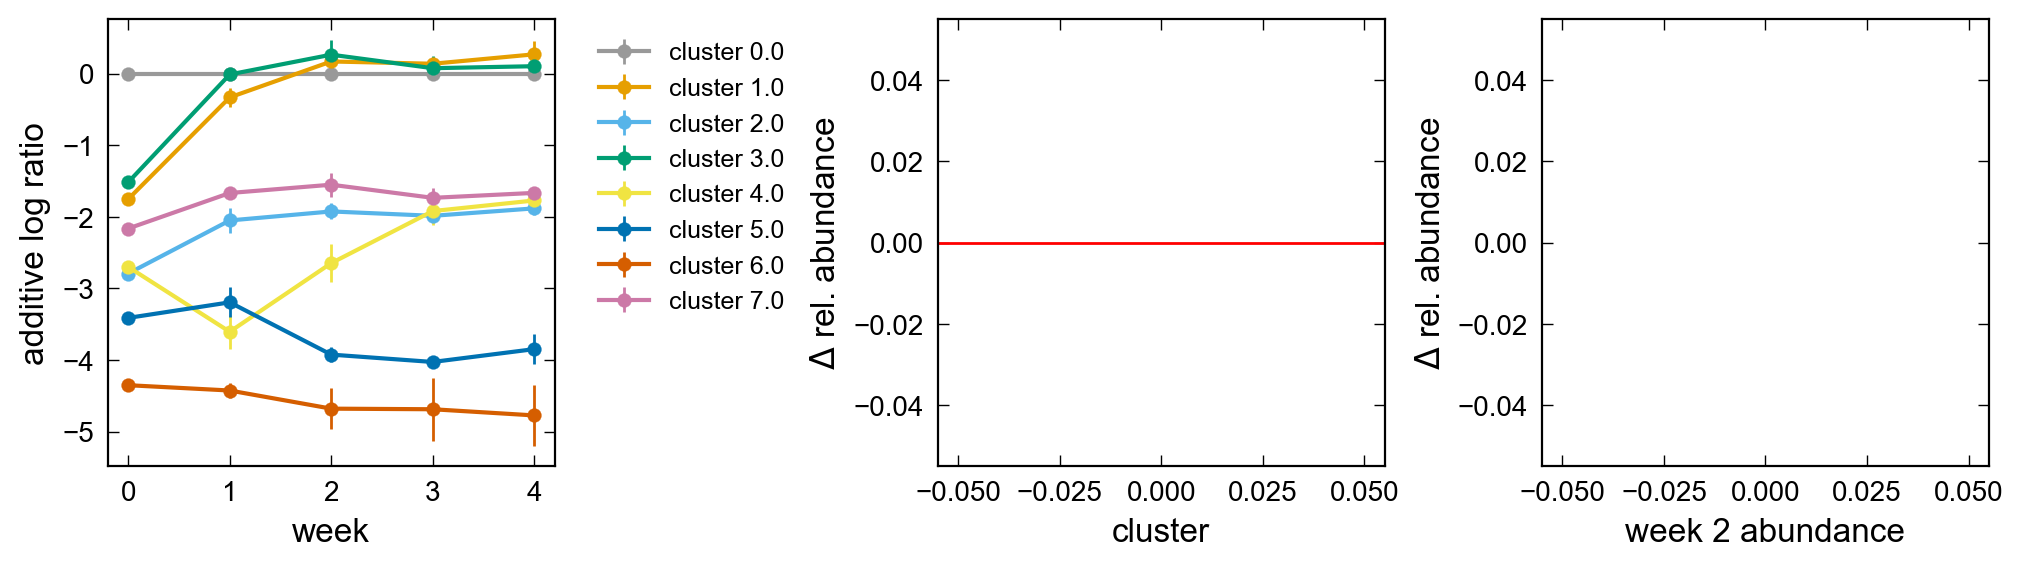

In [57]:
# Plot figures
plot_variables = ['GF_Th17_Average', 'hCom1d_Th17_Average']
cluster_variable= 'cross_reactivity_cluster'
var_list = ['day0_abundance','Batch1_week1_m1',
       'Batch1_week1_m2', 'Batch1_week1_m3', 'Batch1_week1_m4',
       'Batch1_week1_m5', 'Batch1_week2_m1', 'Batch1_week2_m2',
       'Batch1_week2_m3', 'Batch1_week2_m4', 'Batch1_week2_m5',
       'Batch1_week3_m1', 'Batch1_week3_m2', 'Batch1_week3_m3',
       'Batch1_week3_m4', 'Batch1_week3_m5', 'Batch1_week4_m1',
       'Batch1_week4_m2', 'Batch1_week4_m3', 'Batch1_week4_m4',
       'Batch1_week4_m5', 'Batch2_week4_m1', 'Batch2_week4_m2',
       'Batch2_week4_m3', 'Batch3_week4_m1', 'Batch3_week4_m2',
       'Batch3_week4_m3', 'Batch3_week4_m4', 'Batch3_week4_m5']

fig, axs = plt.subplots(1, 3, figsize=(10.0, 3.0), sharex = False, constrained_layout=True)

# Prepare data for plotting
data = full_data_w_clusters[var_list + [cluster_variable]].groupby(cluster_variable, as_index = False).sum()

# Process strain level data
# Compute mean abundance
data.loc[:, 'wk1_mean_abundance'] = np.mean(data[['Batch1_week1_m1','Batch1_week1_m2', 'Batch1_week1_m3', 
                                                                             'Batch1_week1_m4','Batch1_week1_m5']], axis = 1)
data.loc[:, 'wk2_mean_abundance'] = np.mean(data[['Batch1_week2_m1', 'Batch1_week2_m2','Batch1_week2_m3', 
                                                                             'Batch1_week2_m4', 'Batch1_week2_m5']], axis = 1)
data.loc[:, 'wk3_mean_abundance'] = np.mean(data[['Batch1_week3_m1', 'Batch1_week3_m2', 'Batch1_week3_m3', 
                                                                             'Batch1_week3_m4', 'Batch1_week3_m5']], axis = 1)
data.loc[:, 'wk4_mean_abundance'] = np.mean(data[['Batch1_week4_m1','Batch1_week4_m2', 'Batch1_week4_m3', 'Batch1_week4_m4',
                                                                             'Batch1_week4_m5']], axis = 1)

strain_data = pd.concat([data.copy().head(1)[[cluster_variable, 'day0_abundance','wk1_mean_abundance', 'wk2_mean_abundance','wk3_mean_abundance','wk4_mean_abundance']],
                         full_data_w_clusters.loc[(full_data_w_clusters.imm_resp_flag > 0), [cluster_variable, 'day0_abundance', 'wk1_mean_abundance', 'wk2_mean_abundance','wk3_mean_abundance','wk4_mean_abundance']]])
strain_data.loc[:,'strain_id'] = np.array(['nonimmunogenic_cluster'] + full_data_w_clusters.loc[(full_data_w_clusters.imm_resp_flag > 0)].strain_id.tolist())
strain_data.loc[:,['day0_abundance_alr', 'wk1_mean_abundance_alr', 'wk2_mean_abundance_alr','wk3_mean_abundance_alr','wk4_mean_abundance_alr']] = strain_data[['day0_abundance', 'wk1_mean_abundance', 'wk2_mean_abundance','wk3_mean_abundance','wk4_mean_abundance']].copy().apply(alr_transform, axis=0)

mean_strain_array = strain_data[[cluster_variable, 'day0_abundance_alr', 'wk1_mean_abundance_alr', 'wk2_mean_abundance_alr','wk3_mean_abundance_alr','wk4_mean_abundance_alr']].values

# Compute mean abundance
data[var_list] = data[var_list].apply(alr_transform, axis=0)
data.loc[:, 'wk1_mean_abundance'] = np.mean(data[['Batch1_week1_m1','Batch1_week1_m2', 'Batch1_week1_m3', 
                                                                             'Batch1_week1_m4','Batch1_week1_m5']], axis = 1)
data.loc[:, 'wk2_mean_abundance'] = np.mean(data[['Batch1_week2_m1', 'Batch1_week2_m2','Batch1_week2_m3', 
                                                                             'Batch1_week2_m4', 'Batch1_week2_m5']], axis = 1)
data.loc[:, 'wk3_mean_abundance'] = np.mean(data[['Batch1_week3_m1', 'Batch1_week3_m2', 'Batch1_week3_m3', 
                                                                             'Batch1_week3_m4', 'Batch1_week3_m5']], axis = 1)
data.loc[:, 'wk4_mean_abundance'] = np.mean(data[['Batch1_week4_m1','Batch1_week4_m2', 'Batch1_week4_m3', 'Batch1_week4_m4',
                                                                             'Batch1_week4_m5']], axis = 1)

# Compute standard deviation of abundance
data.loc[:, 'wk0_std_abundance'] = 0*np.std(data.day0_abundance)
data.loc[:, 'wk1_std_abundance'] = np.std(data[['Batch1_week1_m1','Batch1_week1_m2', 'Batch1_week1_m3', 
                                                                             'Batch1_week1_m4','Batch1_week1_m5']], axis = 1)
data.loc[:, 'wk2_std_abundance'] = np.std(data[['Batch1_week2_m1', 'Batch1_week2_m2','Batch1_week2_m3', 
                                                                             'Batch1_week2_m4', 'Batch1_week2_m5']], axis = 1)
data.loc[:, 'wk3_std_abundance'] = np.std(data[['Batch1_week3_m1', 'Batch1_week3_m2', 'Batch1_week3_m3', 
                                                                             'Batch1_week3_m4', 'Batch1_week3_m5']], axis = 1)
data.loc[:, 'wk4_std_abundance'] = np.std(data[['Batch1_week4_m1','Batch1_week4_m2', 'Batch1_week4_m3', 'Batch1_week4_m4',
                                                                             'Batch1_week4_m5']], axis = 1)

mean_array = data[[cluster_variable, 'day0_abundance', 'wk1_mean_abundance', 'wk2_mean_abundance','wk3_mean_abundance','wk4_mean_abundance']].values
std_array = data[[cluster_variable, 'wk0_std_abundance','wk1_std_abundance', 'wk2_std_abundance','wk3_std_abundance','wk4_std_abundance']].values
x_data = np.array([0, 1, 2, 3, 4])

# Plot figure
for k, y in enumerate(mean_array):
    # ax.errorbar(x_data, y[1:],
    #     yerr = null_model_std_data[k,1:],elinewidth = 0.1,linewidth = 0.1,fmt = '-', color = ito_colors[k], capsize = 2.0, capthick = 2.0)
    axs[0].errorbar(x_data, y[1:],
                yerr = std_array[k,1:],elinewidth = 1.0,linewidth = 1.5,fmt = '-o', color = ito_colors[k], label = 'cluster '+str(y[0]))

    for s in mean_strain_array:
        cluster = np.unique(mean_array[:,0]).tolist().index(s[0])
        if cluster != 0:
            axs[0].plot(x_data, s[1:], linewidth = 0.5, color = ito_colors[cluster], alpha = 0.5)

for_analysis = strain_data.copy()
for_analysis.loc[:, 'del_abundance'] = for_analysis['wk3_mean_abundance_alr'] - for_analysis['wk2_mean_abundance_alr']

axs[1].scatter(for_analysis['cross_reactivity_cluster'], for_analysis['del_abundance'], 
               s = 1 + 10*for_analysis['wk2_mean_abundance'],
              facecolors='none', edgecolors='black')
axs[1].axhline(y = 0.0, color = 'red')
#for_analysis.boxplot(column='del_abundance', by='cross_reactivity_cluster', ax=axs[1])

axs[2].scatter(for_analysis['wk2_mean_abundance'], for_analysis['del_abundance'], 
               # s = 1 + 10*for_analysis['wk2_mean_abundance'],
              facecolors='none', edgecolors='black')

# Format figure
for j, ax in enumerate(axs.flat):
    ax.legend(bbox_to_anchor=(1.05, 1.0), fontsize=9, framealpha=0)
    if j == 0:
        ax.set_xlabel('week', fontsize = 12)
        ax.set_ylabel(r'additive log ratio', fontsize = 12)
    elif j == 1:
        ax.set_xlabel('cluster', fontsize = 12)
        ax.set_ylabel(r'$\Delta$ rel. abundance', fontsize = 12)
    elif j == 2:
        ax.set_xlabel(r'week 2 abundance', fontsize = 12)
        ax.set_ylabel(r'$\Delta$ rel. abundance', fontsize = 12)
        
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

# plt.savefig('_figs/fig5_'+comment+'-perf_perturb_design'+'.pdf', format="pdf", transparent=True, dpi=300)

/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


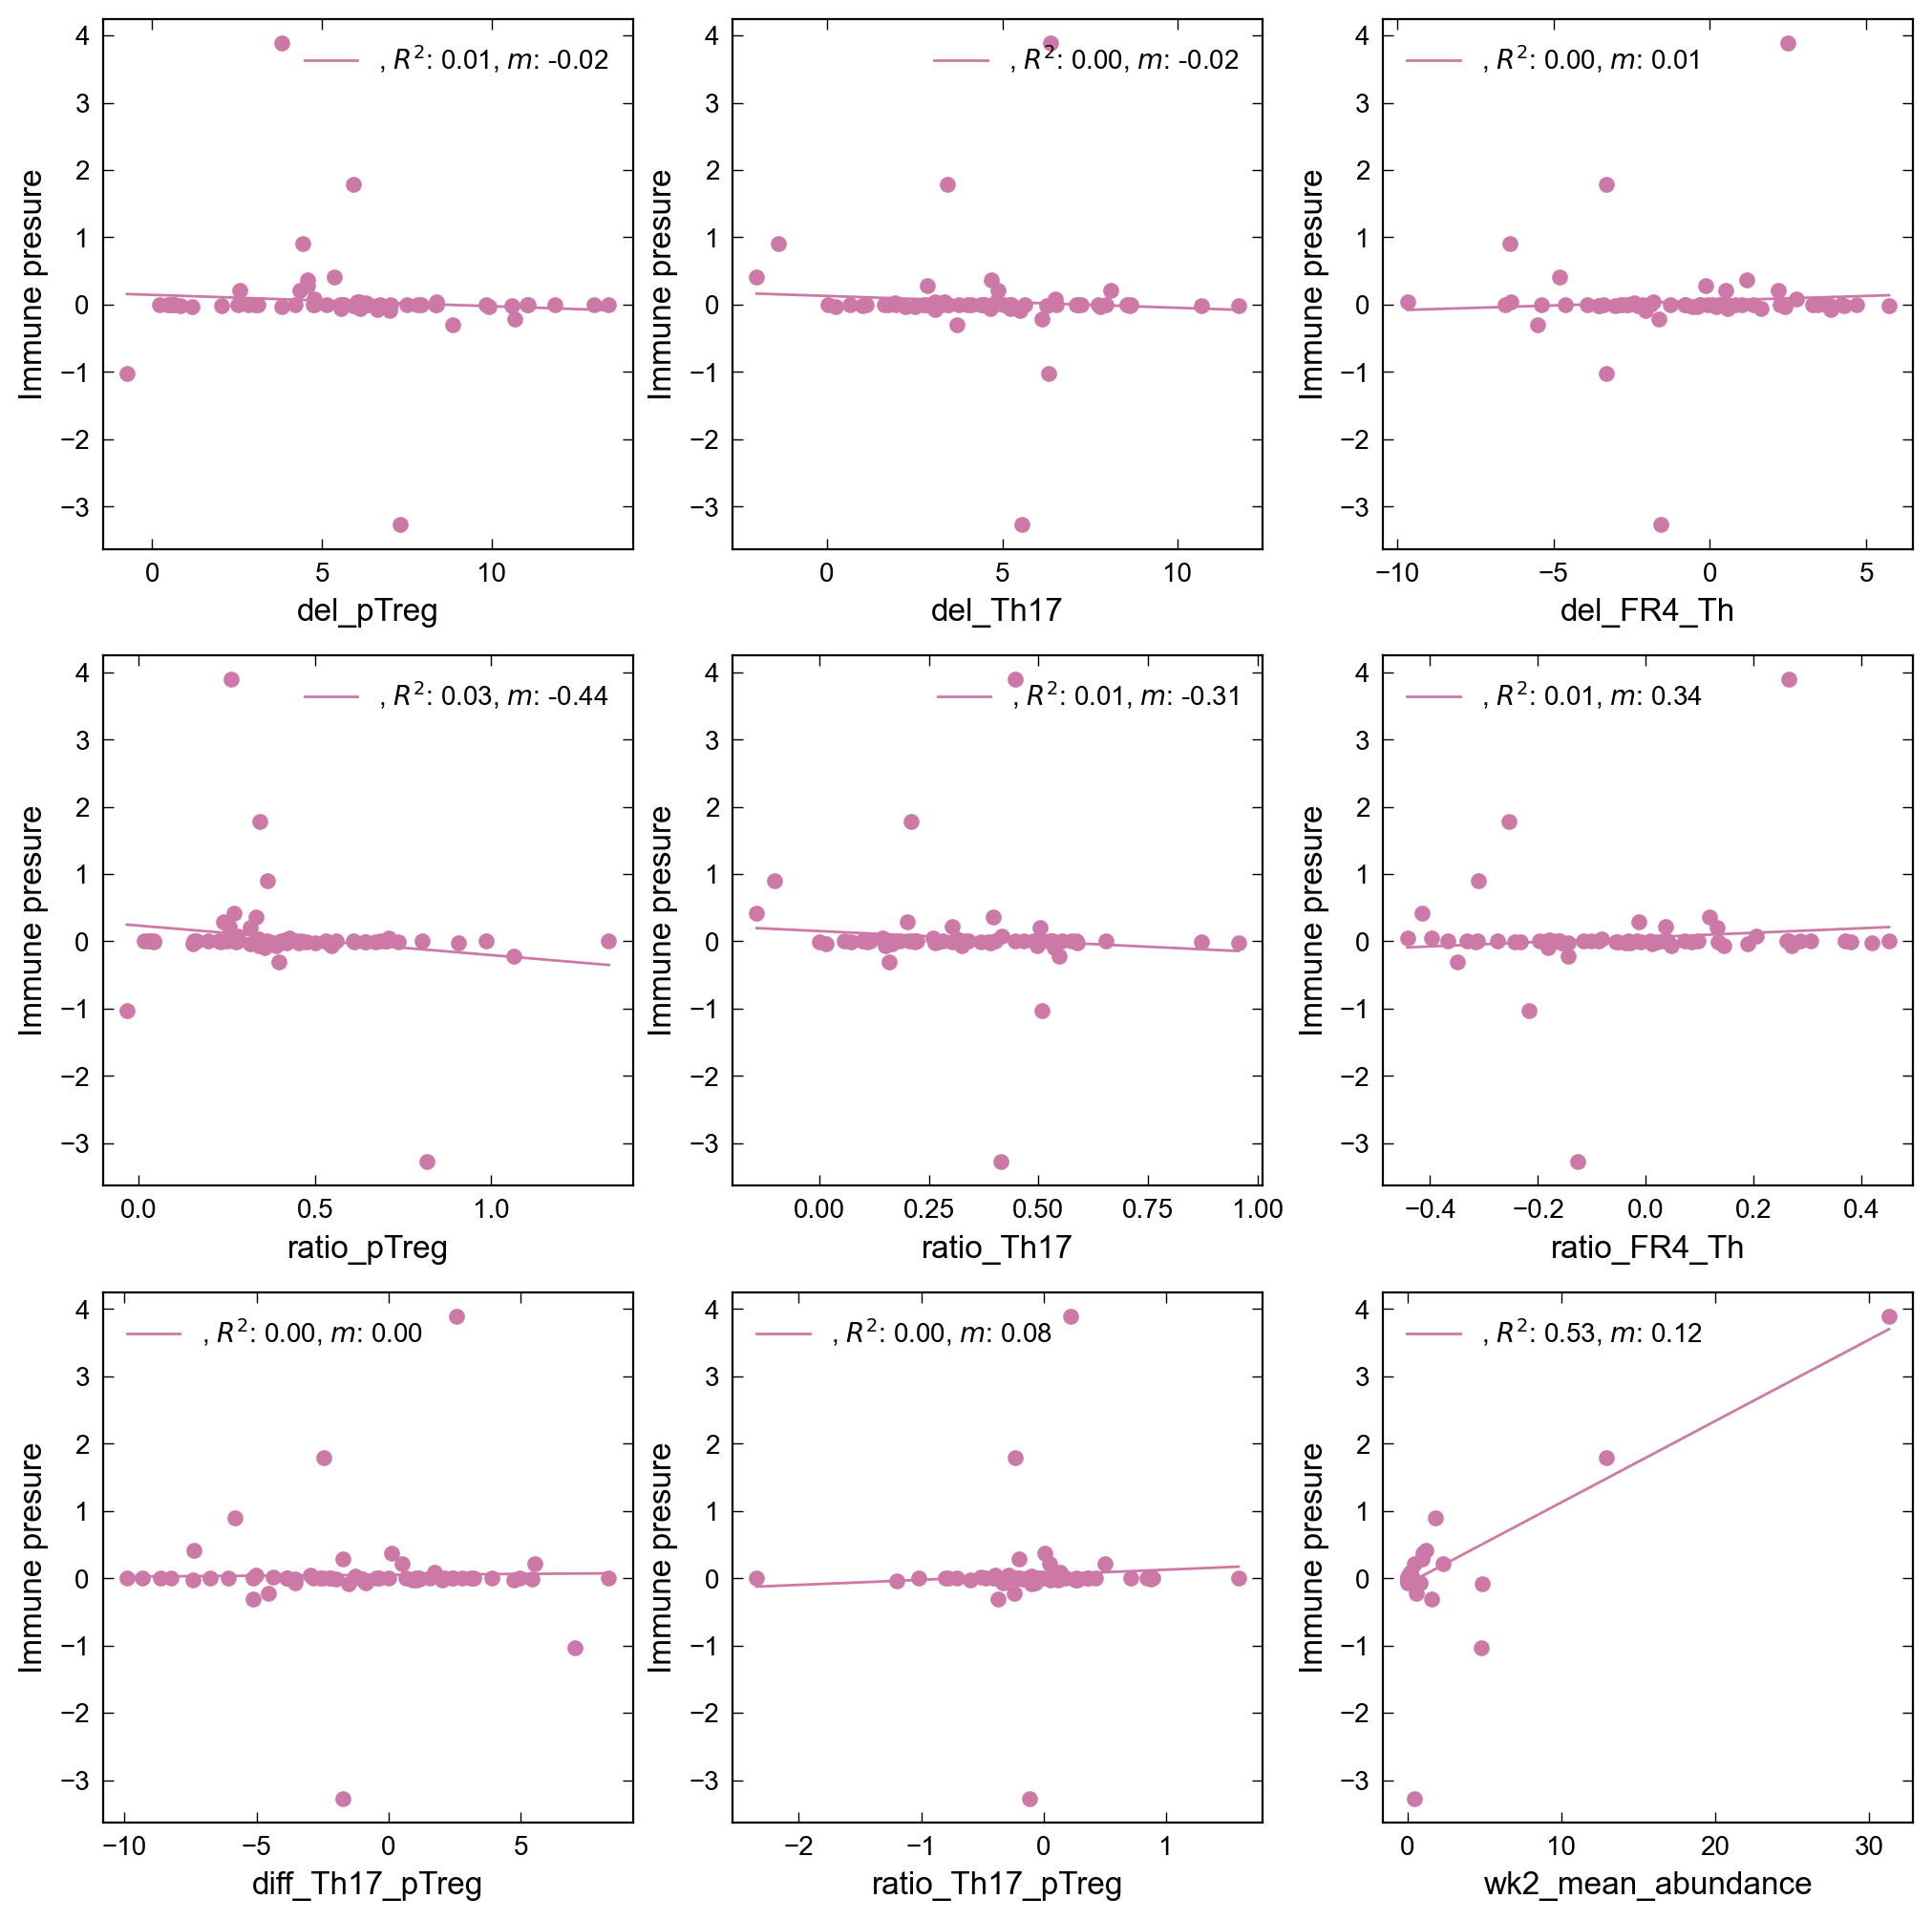

In [58]:
coverage_variables = ['GF_pTreg_Average', 'hCom1d_pTreg_Average', 
                      'GF_Th17_Average', 'hCom1d_Th17_Average', 
                      'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']

for_analysis = full_data_w_clusters.loc[full_data_w_clusters.cross_reactivity_cluster.notna(), ['strain_id'] + coverage_variables].merge(strain_data[['strain_id', 'cross_reactivity_cluster', 'day0_abundance', 'wk1_mean_abundance', 'wk2_mean_abundance','wk3_mean_abundance','wk4_mean_abundance']], 
                               how = 'left', on = 'strain_id', validate = 'one_to_one')
for_analysis.loc[:, 'max_abundance'] = for_analysis['wk3_mean_abundance']
for_analysis.loc[:, 'del_abundance'] = -(for_analysis['wk3_mean_abundance'] - for_analysis['wk2_mean_abundance'])
for_analysis.loc[:, 'del_pTreg'] = for_analysis['hCom1d_pTreg_Average'] - for_analysis['GF_pTreg_Average']
for_analysis.loc[:, 'del_Th17'] = for_analysis['hCom1d_Th17_Average'] - for_analysis['GF_Th17_Average']
for_analysis.loc[:, 'del_FR4_Th'] = for_analysis['hCom1d_FR4_Th_Average'] - for_analysis['GF_FR4_Th_Average']
for_analysis.loc[:, 'ratio_pTreg'] = np.log10(for_analysis['hCom1d_pTreg_Average']/for_analysis['GF_pTreg_Average'])
for_analysis.loc[:, 'ratio_Th17'] = np.log10(for_analysis['hCom1d_Th17_Average']/for_analysis['GF_Th17_Average'])
for_analysis.loc[:, 'ratio_FR4_Th'] = np.log10(for_analysis['hCom1d_FR4_Th_Average']/for_analysis['GF_FR4_Th_Average'])
for_analysis.loc[:, 'diff_Th17_pTreg'] = for_analysis['del_Th17'] - for_analysis['del_pTreg']
for_analysis.loc[:, 'ratio_Th17_pTreg'] = np.log10(for_analysis['del_Th17']/for_analysis['del_pTreg'])
for_analysis.loc[:, 'ratio_FR4_Th_pTreg'] = np.log10(for_analysis['del_FR4_Th']/for_analysis['del_pTreg'])

indep_variables = ['del_pTreg', 'del_Th17', 'del_FR4_Th',
                      'ratio_pTreg', 'ratio_Th17', 'ratio_FR4_Th',
                  'diff_Th17_pTreg', 'ratio_Th17_pTreg', 'wk2_mean_abundance']

# Plot figures
fig, axs = plt.subplots(3, 3, figsize=(10.0, 10.0), sharex = False, constrained_layout=True)
clusters = np.unique(for_analysis['cross_reactivity_cluster'])

for i, ax in enumerate(axs.flat):
    x_data = for_analysis[indep_variables[i]].values
    y_data = for_analysis['del_abundance'].values
    z_data = (for_analysis['max_abundance']+ np.abs(np.amin(for_analysis['max_abundance']))).values + 1
    ax.scatter(x_data, 
               y_data,
              color = ito_colors[l])

    mask = ~np.isnan(x_data) & ~np.isinf(x_data) & ~np.isnan(y_data) & ~np.isinf(y_data)
    # z_data = (for_analysis['max_abundance'][mask] + np.abs(np.amin(for_analysis['max_abundance'][mask]))).values + 1
    if np.sum(mask) >= 2:
        reg = LinearRegression().fit(x_data[mask].reshape(-1, 1), y_data[mask]) #, sample_weight = z_data)
        r_sq = reg.score(x_data[mask].reshape(-1, 1), y_data[mask]) #, sample_weight = z_data)
        m = reg.coef_[0]
        b = reg.intercept_
        #m, b, r_value, p_value, std_err = scipy.stats.linregress(x_data[mask], y_data[mask])
        ax.plot(np.unique(x_data[mask]), 
                m*np.unique(x_data[mask]) + b, 
                label = r', $R^2$: ' + str("{:.2f}".format(r_sq))+ r', $m$: ' + str("{:.2f}".format(m)), color = ito_colors[l])

for j, ax in enumerate(axs.flat):
    ax.legend()
    # ax.semilogx()
    # ax.semilogy()
    ax.set_xlabel(indep_variables[j], fontsize = 12)
    ax.set_ylabel('Immune presure', fontsize = 12)
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

# plt.savefig('_figs/fig5_'+comment+'-perf_perturb_design'+'.pdf', format="pdf", transparent=True, dpi=300)

In [59]:
# ALR makes sense as a quantity of interest. It conveniently removes the total biomass from the abundance relationship between two species and is something my model can predict.
# (1) Want to regress week 2 - week 4 change in alr on mean (maybe geometric) immune coverage within the cluster. Is there signal?
# (2) Compare all species within the immune-covered clusters to the reference (non-immune coverage) cluster
# (3) Combine strain and amino acid dropout variables into a single clustering step

33 59


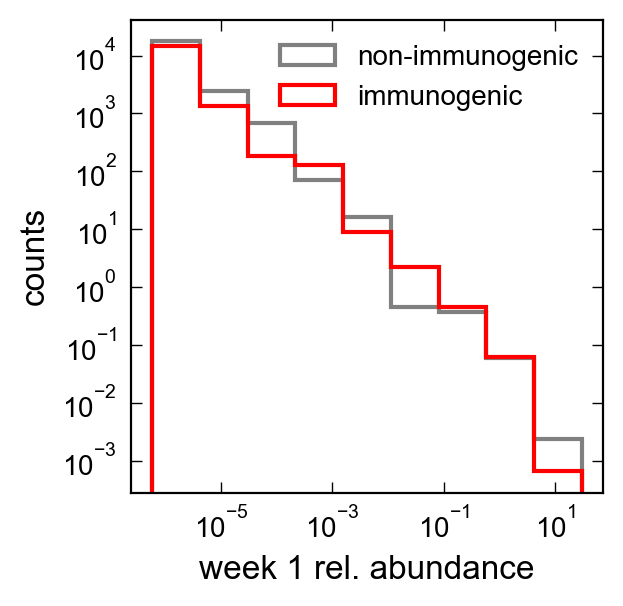

In [60]:
# Plot figures
fig, ax = plt.subplots(1, 1, figsize=(3.0, 3.0), sharex = False, constrained_layout=True)

labels = [['strain abundance', 'frequency'], 
          ['day 0', 'day 2'], ['day 0', 'day 14'], ['day 0', 'day 28'], ['day 14', 'day 28']]
var = 'wk1_mean_abundance'

data = full_data_w_clusters.loc[full_data_w_clusters[var] > 0]
start, stop = np.log10(np.nanmin(data[var])), np.log10(np.nanmax(data[var]))
log_bins = 10**np.linspace(start, stop, 10)
# bins = np.linspace(start, stop, 50)

# for k, (_,g) in enumerate(full_data_w_clusters.groupby(['cross_reactivity_cluster'], as_index = False)):
ax.hist(data.loc[data.imm_resp_flag <= 0][var], log = True, 
        bins = log_bins, histtype = 'step', density=True, color = 'gray', 
        linewidth=1.5, label = 'non-immunogenic')
ax.hist(data.loc[data.imm_resp_flag > 0][var], log = True, 
        bins = log_bins, histtype = 'step', density=True, color = 'red', 
        linewidth=1.5, label = 'immunogenic')
    
ax.legend(fontsize=10, framealpha=0, ncol = 1)

ax.set_ylabel('counts', fontsize = 12)
ax.set_xlabel('week 1 rel. abundance', fontsize = 12)
ax.semilogx()
ax.set_box_aspect(1)
ax.minorticks_off()
ax.tick_params(axis='both', which='major', labelsize=10)
ax.xaxis.set_tick_params(labeltop=False)

print(len(data.loc[data.imm_resp_flag <= 0][var]), len(data.loc[data.imm_resp_flag > 0][var])) 

fig.savefig('_figs/fig_hist_rel_abundance_by_imm'+'.png', dpi=300, bbox_inches='tight')

In [61]:
for i, c in enumerate(cluster_variables):
    counts_specific_column = full_data_w_clusters.loc[full_data_w_clusters.Phyla.notna()].fillna(-1).groupby([cluster_variables[i % len(cluster_variables)], cluster_variables[(i + 1) % len(cluster_variables)]])['strain_id'].count()
    # out = pd.crosstab(full_data_w_clusters[cluster_variables[i % len(cluster_variables)], cluster_variables[(i + 1) % len(cluster_variables)]],
    #                    full_data_w_clusters['strain_id'])
    print("\nCounts of 'Strains' using count():")
    print(counts_specific_column)


Counts of 'Strains' using count():
Phyla            strain_drop_cluster
Actinobacteria   1.0                    10
                 4.0                     1
Bacteroidetes    1.0                    29
                 3.0                     2
Firmicutes       1.0                    32
                 2.0                     4
                 3.0                     4
                 4.0                     6
                 5.0                     5
                 6.0                     2
Proteobacteria   1.0                     1
Verrucomicrobia  1.0                     1
Name: strain_id, dtype: int64

Counts of 'Strains' using count():
strain_drop_cluster  amino_drop_cluster
1.0                  1.0                   34
                     2.0                   18
                     3.0                   11
                     4.0                    7
                     5.0                    1
                     6.0                    1
                     7.0     